<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/homeworks/pro/AI_HW1_Regression_with_inference_pro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Домашнее задание №1 (pro)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;


**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–5 (EDA, модели, категориальные признаки, Feature Engineering, бизнес-метрика) — 5 баллов;
- Часть 6, оформление репозитория — 2 балла;
- Часть 7, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
#!pip install -q ydata-profiling "numpy<2.4"  # numba в Colab пока не поддерживает NumPy 2.4

In [2]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

/run/media/phoenix377/DiskD1/HSE/ML/HW_1_HSE_ML/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_10756/1014525522.py:7: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


### **Задание 0**
Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

-Во первых это необходимо для проверки домашних заданий

-Во вторых так зачастую делают не только в домашках , а и в реальных проектах, так как там сид важен для вопсроизводимости (на торче отдельные есть мемы про количество фиксаций , которые надо делать)

# **Часть 1 | EDA**


Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.4 балла)
- Визуализации признаков и их анализ (0.9 балла)

Всего за эту часть можно набрать 2.3 балла.

## **Простейший EDA и обработка признаков (1.4 балла)**

In [3]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.4 балла)**
Выполните операции, направленные на базовое исследование данных:

- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения (0.1 балла)
- [ ] Посмотрите, есть ли в данных явные дубликаты (0.05 балла)
- [ ] Постройте дашборд в одну строку, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling) (0.1 балла)
- [ ] Опишите базовые выводы (какие — выберите сами), используя дашборд (0.15 балла).

**Ваш ответ здесь.**

In [4]:
print("Колонки с пропусками")
print(list(df_train.columns[df_train.isna().sum() > 0]))
print(f"Количество явных дубликатов: {df_train.duplicated().sum()}")

Колонки с пропусками
['mileage', 'engine', 'max_power', 'torque', 'seats']
Количество явных дубликатов: 985


In [5]:
profile_report = ProfileReport(df_train, title='Pandas Profiling Report')
profile_report.to_file('HW_EDA_profile.html')

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 240.65it/s]


In [6]:
profile_report = ProfileReport(df_test, title='Pandas Profiling Report')
profile_report.to_file('HW_EDA_profile_test.html')

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 165.07it/s]


`Your answer here`
1. Размер датасета и дубликаты
В таблице 6999 строк и 13 колонок. Сразу бросается в глаза, что в данных есть 493 полных дубликата (это 7% от всей выборки). Перед обучением модели их точно нужно будет удалить, чтобы данные не дублировались и не искажали результат.
2. Типы данных
Сейчас в таблице только 4 числовых признака, 4 категориальных и целых 5 текстовых. Но если присмотреться, текстовые колонки (вроде мощности двигателя, объема, расхода и крутящего момента) по сути являются числами, просто к ним приписаны единицы измерения. Перед работой с моделями их придется очистить от текста и перевести в обычный числовой формат.
3. Пропуски
Всего в таблице 1005 пропущенных ячеек это около 1.1% от всех данных, что совсем немного. Интересно, что пропуски распределены не хаотично: в пяти технических колонках (mileage, engine, max_power, torque, seats) не хватает примерно по 200 значений (около 2.9% в каждой). Похоже, что в датасете просто есть около двухсот машин с неполной карточкой характеристик.
4. Связи между признаками
• Год выпуска и пробег ожидаемо сильно связаны между собой: чем старше машина, тем больше она проехала. Удалять один из этих признаков не хочется, так как оба важны для цены позже на их основе можно будет посчитать средний пробег за год.
• Цена продажи заметно коррелирует с типом коробки передач. Это вполне логично: автомат чаще ставят в более дорогие модели и богатые комплектации, поэтому такие машины стоят дороже механики.
5. Дисбаланс в категориях
В колонке с типом продавца (seller_type) есть сильный перекос: больше половины объявлений (51.8%) приходится на одну категорию (скорее всего, это частники, а остальное дилеры). Это стоит иметь в виду при дальнейшем кодировании признаков и разбиении данных на обучение и тест.

### **Задание 2 (0.2 балла)**
Проанализируйте статистики датасета.

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сравните среднее и медиану внутри `train`, внутри `test` и между собой. О чём могут говорить результаты?
- [ ] Сделайте выводы по статистикам. Отсутствие выводов равносильно по баллам невыполнению задания.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

In [7]:
df_train.describe(include = "all")

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
count,6999,6999.000000,6.999000e+03,6.999000e+03,6999,6999,6999,6999,6797,6797,6803,6796,6797.000000
unique,1924,NaN,NaN,NaN,4,3,2,5,386,120,316,419,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,NaN
freq,116,NaN,NaN,NaN,3793,5826,6095,4587,197,885,330,468,NaN
mean,NaN,2013.818403,6.395152e+05,6.958462e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.419008
std,NaN,4.053095,8.089419e+05,5.772400e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.965767
min,NaN,1983.000000,2.999900e+04,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
25%,NaN,2011.000000,2.549990e+05,3.500000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
50%,NaN,2015.000000,4.500000e+05,6.000000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
75%,NaN,2017.000000,6.750000e+05,9.700000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000


In [8]:
df_test.describe(include = "all")

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
count,1000,1000.000000,1.000000e+03,1000.000000,1000,1000,1000,1000,981,981,981,981,981.000000
unique,621,NaN,NaN,NaN,4,3,2,5,237,88,182,226,NaN
top,Maruti Alto 800 LXI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,18.6 kmpl,1248 CC,74 bhp,200Nm@ 1750rpm,NaN
freq,15,NaN,NaN,NaN,534,837,877,623,23,116,43,57,NaN
mean,NaN,2013.681000,6.179010e+05,71393.341000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.410805
std,NaN,4.012149,7.585539e+05,48486.218662,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.919985
min,NaN,1995.000000,3.100000e+04,1303.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000
25%,NaN,2011.000000,2.500000e+05,37000.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
50%,NaN,2014.000000,4.349990e+05,61500.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
75%,NaN,2017.000000,6.700000e+05,100000.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000


=== 1. ЧИСЛОВЫЕ СТАТИСТИКИ: TRAIN ===


,count,mean,std,min,25%,50%,75%,max
year,6999.0,2013.818403,4.053095,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,6999.0,639515.197171,808941.911915,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,6999.0,69584.615517,57724.001817,1.0,35000.0,60000.0,97000.0,2360457.0
seats,6797.0,5.419008,0.965767,2.0,5.0,5.0,5.0,14.0



=== 1. ЧИСЛОВЫЕ СТАТИСТИКИ: TEST ===


,count,mean,std,min,25%,50%,75%,max
year,1000.0,2013.681000,4.012149,1995.0,2011.0,2014.0,2017.0,2020.0
selling_price,1000.0,617901.042000,758553.860710,31000.0,250000.0,434999.0,670000.0,6000000.0
km_driven,1000.0,71393.341000,48486.218662,1303.0,37000.0,61500.0,100000.0,375000.0
seats,981.0,5.410805,0.919985,4.0,5.0,5.0,5.0,9.0



=== 2. КАТЕГОРИАЛЬНЫЕ СТАТИСТИКИ: TRAIN ===


,count,unique,top,freq
name,6999,1924,Maruti Swift Dzire VDI,116
fuel,6999,4,Diesel,3793
seller_type,6999,3,Individual,5826
transmission,6999,2,Manual,6095
owner,6999,5,First Owner,4587
mileage,6797,386,18.9 kmpl,197
engine,6797,120,1248 CC,885
max_power,6803,316,74 bhp,330
torque,6796,419,190Nm@ 2000rpm,468



=== 2. КАТЕГОРИАЛЬНЫЕ СТАТИСТИКИ: TEST ===


,count,unique,top,freq
name,1000,621,Maruti Alto 800 LXI,15
fuel,1000,4,Diesel,534
seller_type,1000,3,Individual,837
transmission,1000,2,Manual,877
owner,1000,5,First Owner,623
mileage,981,237,18.6 kmpl,23
engine,981,88,1248 CC,116
max_power,981,182,74 bhp,43
torque,981,226,200Nm@ 1750rpm,57


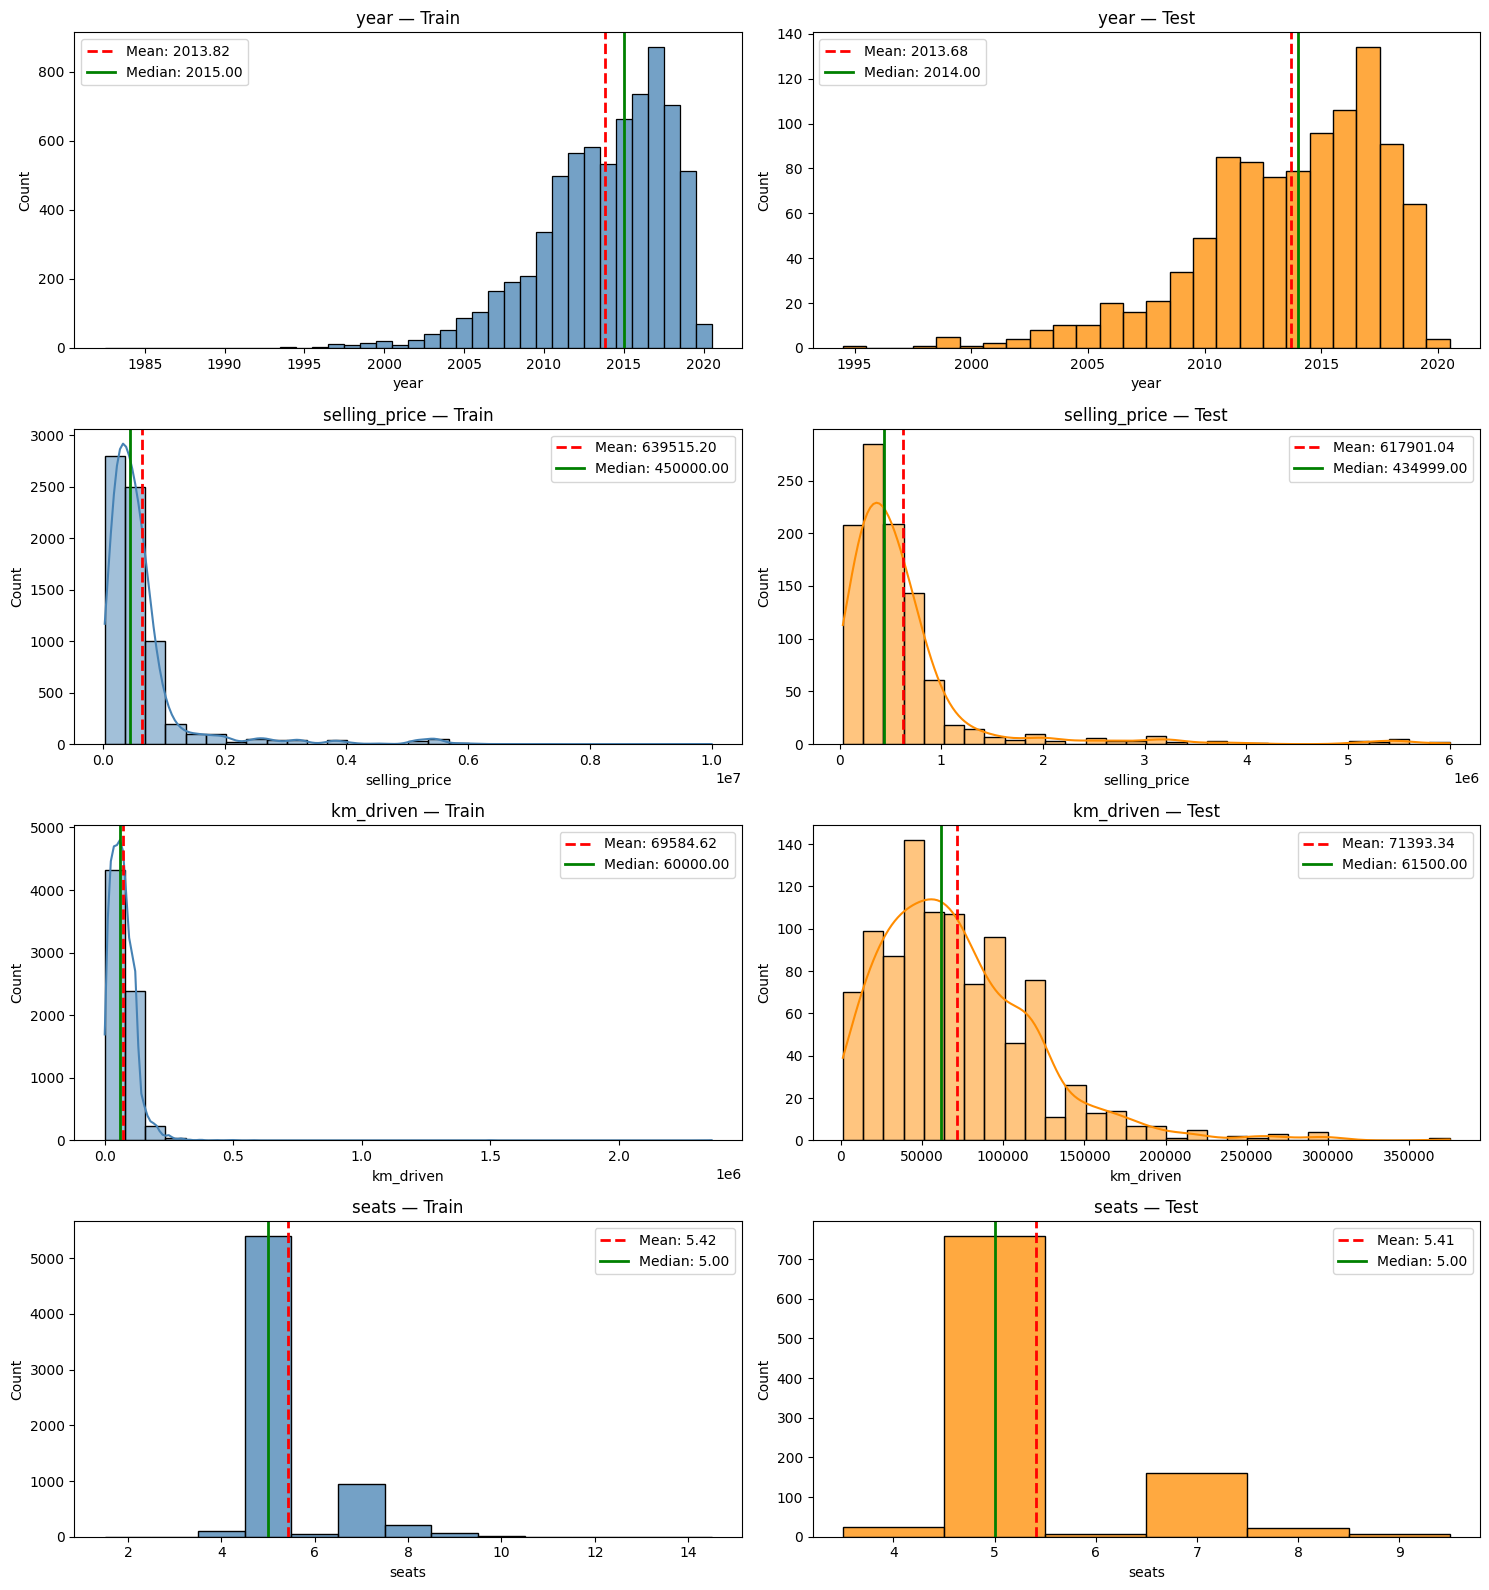

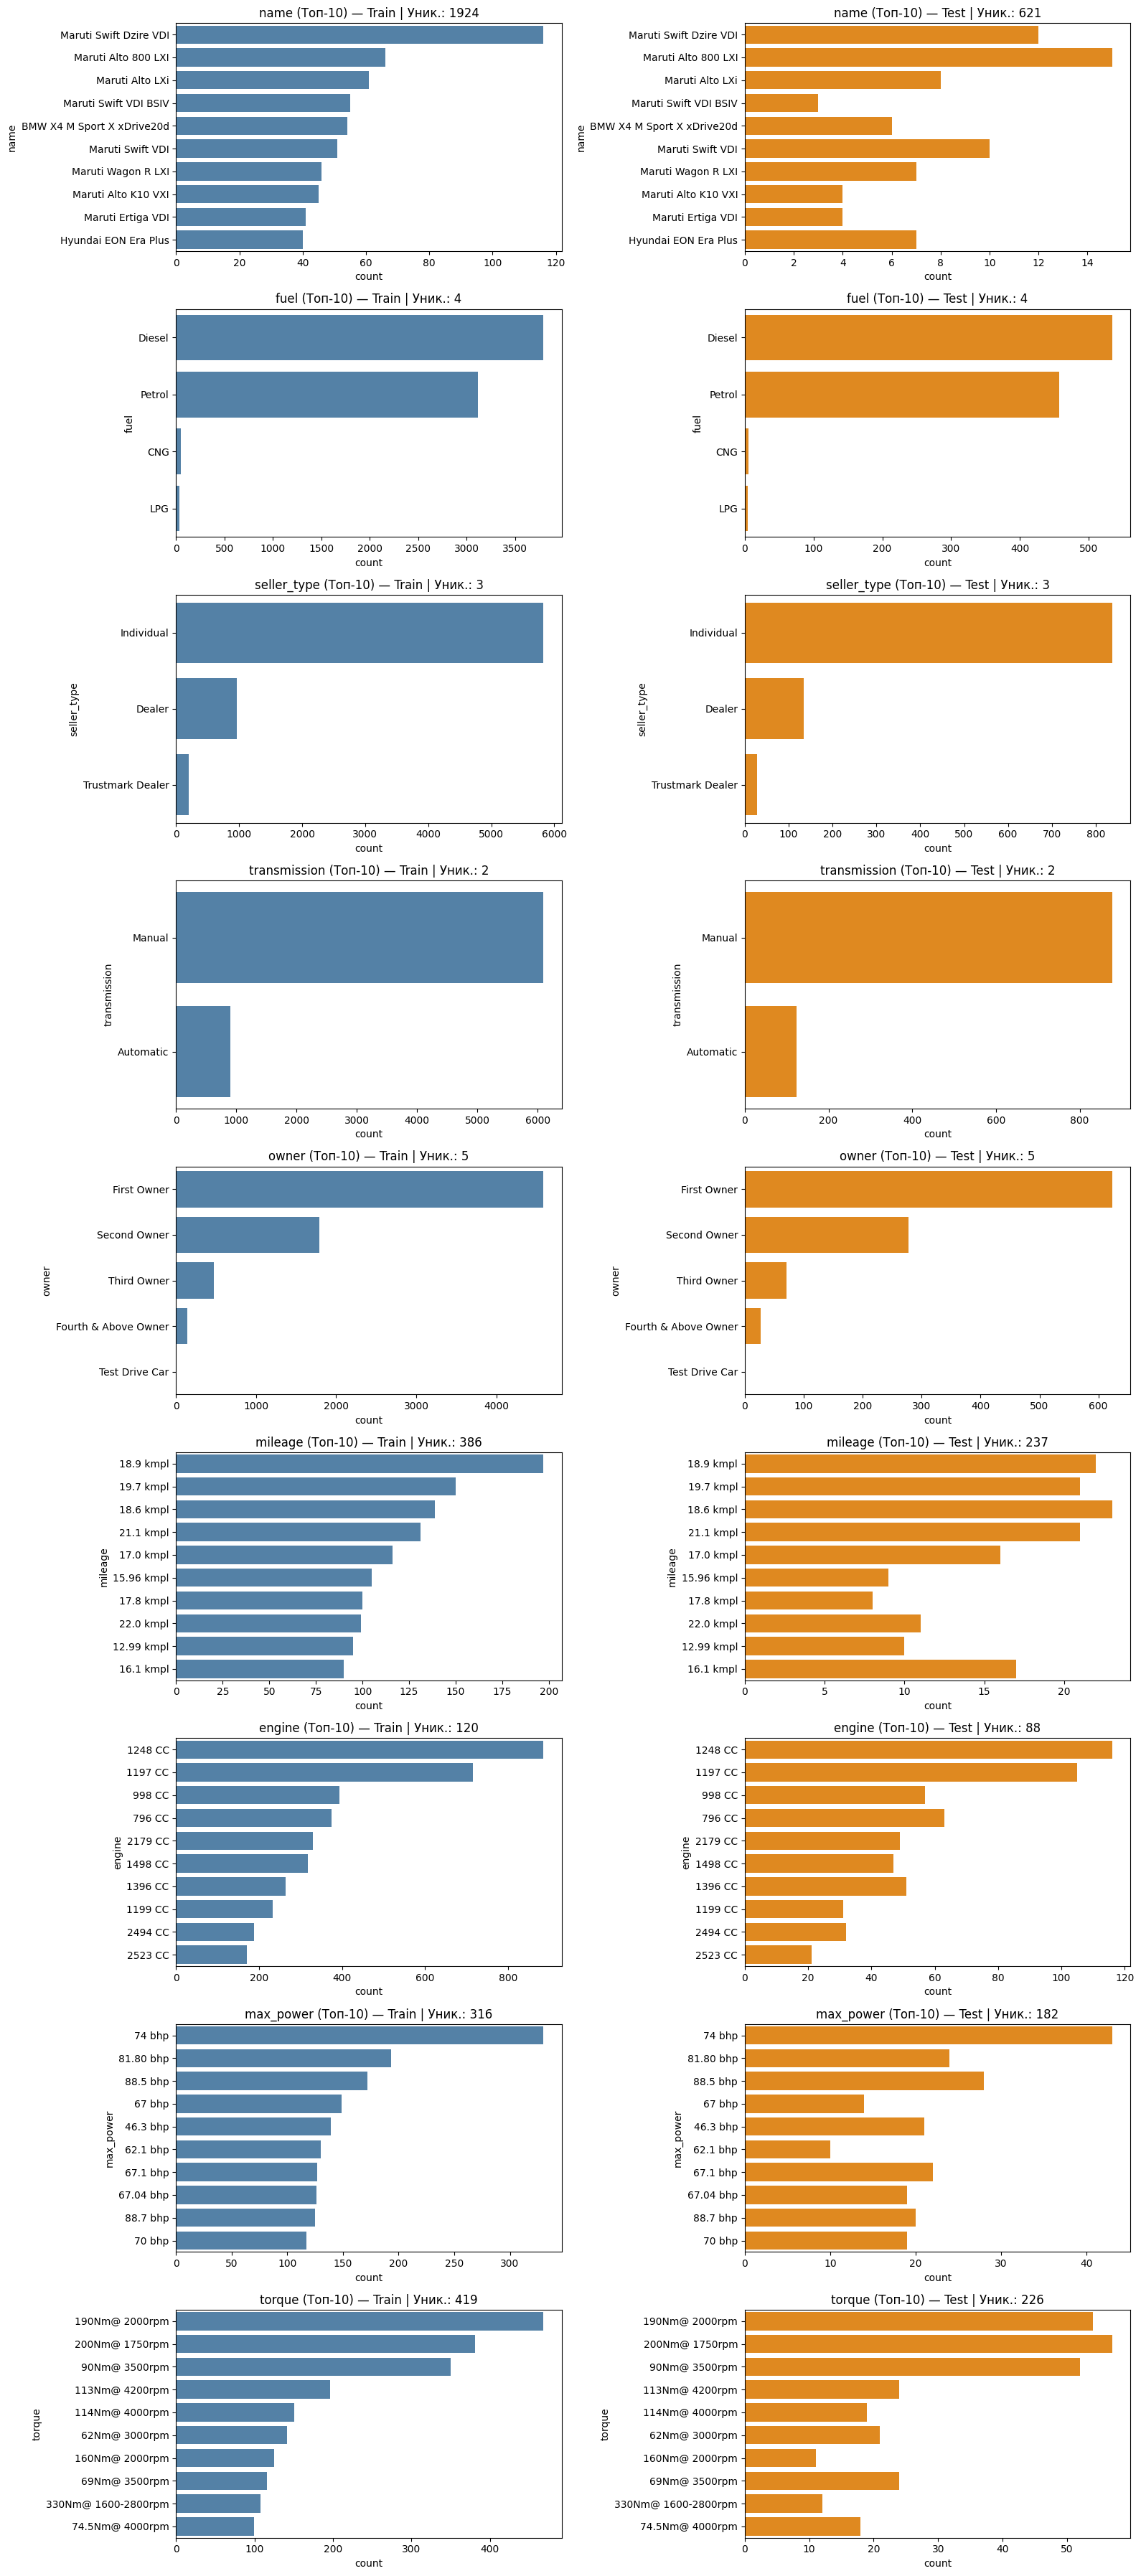

In [9]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

num_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_train.select_dtypes(exclude=[np.number]).columns.tolist()

print("=== 1. ЧИСЛОВЫЕ СТАТИСТИКИ: TRAIN ===")
display(df_train[num_cols].describe().T)

print("\n=== 1. ЧИСЛОВЫЕ СТАТИСТИКИ: TEST ===")
display(df_test[num_cols].describe().T)

print("\n=== 2. КАТЕГОРИАЛЬНЫЕ СТАТИСТИКИ: TRAIN ===")
display(df_train[cat_cols].describe().T)

print("\n=== 2. КАТЕГОРИАЛЬНЫЕ СТАТИСТИКИ: TEST ===")
display(df_test[cat_cols].describe().T)

if num_cols:
    fig, axes = plt.subplots(nrows=len(num_cols), ncols=2, figsize=(15, 4 * len(num_cols)))
    if len(num_cols) == 1:
        axes = np.array([axes])

    for i, col in enumerate(num_cols):
        is_discrete = df_train[col].nunique() < 40
        hist_kwargs = {'discrete': True} if is_discrete else {'bins': 30}

        sns.histplot(df_train[col], kde=not is_discrete, ax=axes[i, 0], color='steelblue', **hist_kwargs)
        axes[i, 0].axvline(df_train[col].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {df_train[col].mean():.2f}")
        axes[i, 0].axvline(df_train[col].median(), color='green', linestyle='-', linewidth=2, label=f"Median: {df_train[col].median():.2f}")
        axes[i, 0].set_title(f"{col} — Train")
        axes[i, 0].legend()

        sns.histplot(df_test[col], kde=not is_discrete, ax=axes[i, 1], color='darkorange', **hist_kwargs)
        axes[i, 1].axvline(df_test[col].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {df_test[col].mean():.2f}")
        axes[i, 1].axvline(df_test[col].median(), color='green', linestyle='-', linewidth=2, label=f"Median: {df_test[col].median():.2f}")
        axes[i, 1].set_title(f"{col} — Test")
        axes[i, 1].legend()

    plt.tight_layout()
    display(fig)
    plt.close(fig)

if cat_cols:
    fig, axes = plt.subplots(nrows=len(cat_cols), ncols=2, figsize=(16, 4 * len(cat_cols)))
    if len(cat_cols) == 1:
        axes = np.array([axes])

    for i, col in enumerate(cat_cols):
        top_10 = df_train[col].value_counts().nlargest(10).index
        
        sns.countplot(data=df_train[df_train[col].isin(top_10)], y=col, order=top_10, ax=axes[i, 0], color='steelblue')
        axes[i, 0].set_title(f"{col} (Топ-10) — Train | Уник.: {df_train[col].nunique()}")

        sns.countplot(data=df_test[df_test[col].isin(top_10)], y=col, order=top_10, ax=axes[i, 1], color='darkorange')
        axes[i, 1].set_title(f"{col} (Топ-10) — Test | Уник.: {df_test[col].nunique()}")

    plt.tight_layout()
    display(fig)
    plt.close(fig)


Выводы
1. В цене продажи в train и test сильный сдвиг в сторону среднего. Значит, зачастую продают средние по цене автомобили, ближе к «ниже среднего» (очевидно, это масс-маркет), но иногда встречаются очень дорогие продажи за огромные суммы денег. Ситуация аналогична как в train, так и в test. Отсюда можно сделать вывод, что таргет-переменная распределена одинаково и сдвига в данных нет → валидация модели будет верной.
2. В цене большие длинные хвосты, что является не аномалией, а просто краевыми случаями. Возможно, надо будет уходить от выбросов через MAE или через логарифмирование для выравнивания кривой (MSE может быть не очень хорошим вариантом).
3. В train диапазон цен больше, чем в test. Фактически это хорошо, так как распределение train шире, чем test, но здесь снова поднимается вопрос из 2-го пункта.
4. Год автомобилей в основном более свежий, но масса старых авто тянет среднее вниз (median > mean).
5. С пробегом ситуация обратная: там в основном у машин пробег меньше, но есть пара авто с огромным пробегом — очень редкие случаи (median < mean).
6. Категориальные признаки max_power, torque, engine, mileage это числовые признаки, просто записанные строками. Их надо будет преобразовать в числа, так как это важные характеристики авто.
7. По частоте признаки в train и test для name, fuel, seller_type, transmission, owner схожи, что отлично и даст нам возможность обучиться и верно проверить работоспособность модели data shift не случится.
8. Name не индивидуальный признак, а по факту ID вида машины, и он повторяется, значит, будем кодировать.
9. Дисбаланс категорий между train и test отсутствует — выборки однородны
10. Владельцов можно как последовательное кодирование сделать так как смысл передается возводя 1 2 3 4 количество людей кто владел



### **Задание 3 (0.2 балла)**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.01 балла)
- [ ] Отобразите такие объекты (0.01 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.01 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.01 балла)
- [ ] Подумайте, могут ли в данных быть другие скрытые дубли? Предложите, как их можно отлавливать. (0.16 балла)

P.S. Тут данные без подвоха, но выводы нам нужны.

In [10]:
target = "selling_price"
feature_col = [col for col in df_train.columns if col != target]

print("Количество дубликатов (по признакам):", df_train.duplicated(subset=feature_col).sum())

display(df_train[df_train.duplicated(subset=feature_col, keep=False)].sort_values(by=feature_col))

df_train = df_train.drop_duplicates(subset=feature_col, keep='first').reset_index(drop=True)
print("Размер df_train после удаления:", df_train.shape)

Количество дубликатов (по признакам): 1159


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1703,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
6307,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
1836,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
6704,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
117,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5637,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5652,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5753,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0
5991,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.0


Размер df_train после удаления: (5840, 13)


Скрытые дубли, конечно, могут быть: продавцы нередко выкладывают несколько объявлений об одной машине, слегка меняя пробег или цену, либо меняется продавец (например, частник продал машину дилеру). Также возможны опечатки и разный формат записи при вводе данных.
Отлавливать их можно тремя способами: искать совпадения по неизменным техническим характеристикам (name, year, fuel, transmission, engine, max_power) с допуском небольшой разницы в пробеге km_driven (в пределах 1–3 тыс. км); привести все текстовые столбцы к единому формату (убрать лишние пробелы, привести к нижнему регистру, а mileage, engine, max_power, torque очистить от единиц измерения и перевести в числа); проверять дубликаты без учёта столбцов с пропусками NaN, так как пустое поле в одном из объявлений мешает обычному поиску совпадений.

In [11]:
assert df_train.shape == (5840, 13)

### **Задание 4 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Предобработайте признак `torque` — разделите его на два: собственно `torque` и `max_torque_rpm`. Учтите единицы измерения


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.

In [12]:
for df in [df_train, df_test]:
    for col in ['mileage', 'engine', 'max_power']:
        df[col] = df[col].astype(str).str.extract(r'(\d+\.?\d*)').astype(float)

for df in [df_train, df_test]:
    s = df['torque'].astype(str).str.replace(',', '')
    df['torque'] = s.str.extract(r'^(\d+\.?\d*)').astype(float)
    df.loc[s.str.contains('kgm', case=False, na=False), 'torque'] *= 9.80665
    df['max_torque_rpm'] = s.str.extract(r'(\d+\.?\d*)\s*rpm', flags=2).astype(float)

### **Задание 5 (0.15 балла)**

На первом шаге мы обнаружили пропуски. Давайте избавимся от них.

**Задание:**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось.
- [ ] Почему стоит применять именно медиану? Могли ли мы применить среднее? Обоснуйте свое рассуждение.
- [ ] Как правильно считать медиану для заполнения? Выберите верное утверждение:
 - По тестовым свою, по тренировочным — свою
 - По тренировочным данным для `train` и `test`

In [13]:
num_cols = df_train.select_dtypes(include=[np.number]).columns.drop('selling_price', errors='ignore')

for col in num_cols:
    fill_value = df_train[col].median()
    skew = df_train[col].skew()
    n_train = df_train[col].isna().sum()
    n_test = df_test[col].isna().sum()
    
    df_train[col] = df_train[col].fillna(fill_value)
    df_test[col] = df_test[col].fillna(fill_value)
    
    if n_train > 0 or n_test > 0:
        print(f'{col:>15}: skew = {skew:5.2f} | median = {fill_value:7.2f} | пропусков train/test: {n_train}/{n_test}')

print("\nОсталось пропусков в train:", df_train.isna().sum().sum())
print("Осталось пропусков в test:", df_test.isna().sum().sum())

        mileage: skew = -0.17 | median =   19.37 | пропусков train/test: 186/19
         engine: skew =  1.22 | median = 1248.00 | пропусков train/test: 186/19
      max_power: skew =  1.76 | median =   81.86 | пропусков train/test: 184/19
         torque: skew =  8.51 | median =  160.00 | пропусков train/test: 187/19
          seats: skew =  1.96 | median =    5.00 | пропусков train/test: 186/19
 max_torque_rpm: skew =  0.14 | median = 3000.00 | пропусков train/test: 525/72

Осталось пропусков в train: 0
Осталось пропусков в test: 0


Медиану стоит применять потому, что она устойчива к выбросам и сильной асимметрии распределения. По результатам расчётов видно, что у большинства признаков с пропусками наблюдается сильная правая асимметрия: engine (skew = 1.22), max_power (skew = 1.76), seats (skew = 1.96) и особенно torque (skew = 8.51). Наличие редких мощных автомобилей с запредельными характеристиками сильно смещает среднее значение вверх, тогда как медиана отражает типичный автомобиль (а для дискретного признака seats ещё и сохраняет корректное целое значение 5.0). Применить среднее можно было бы только для признаков без сильного скоса, где |skew|  в районе < 0.5  а  в наших данных это mileage (skew = -0.17) и max_torque_rpm (skew = 0.14), но использование медианы для всех столбцов делает предобработку единой и не усложняет.
Надо выбирать среднее только по тренировочным данным для train и test. Использование статистик из test привело бы к утечке данных  и завышению оценки качества, а в реальной эксплуатации новые объекты могут поступать по одному, где посчитать медиану по тесту невозможно.

### **Задание 6 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.
- [ ] Ответьте на вопрос — почему ``seats`` (хоть мы этого и не делаем) можно рассматривать как категориальную переменную?

In [14]:
for df in [df_train, df_test]:
    df["engine"] = df["engine"].astype(int)
    df["seats"] = df["seats"].astype(int)

Seats можно рассматривать как категориальную переменную, потому что у неё конечное количество возможных вариантов, плюс это в какой-то степени порядковая переменная, так как она отражает величину вместимости. На обучение в случае линейных моделей это повлияет очень сильно: если мы оставим int, признак будет оказывать строго линейное влияние, хотя, скорее всего, количество мест нелинейно влияет на цену, и для учёта этого нужно делать кодирование признака (например, One-Hot Encoding).

### **Задание 7 (0.1 балла)**

Снова вызовите метод describe и проанализируйте статистики.

**Ответьте на вопрос:**
- [ ] Есть ли основания предполагать, что заполнение пропусков сдвинуло наши распределения? Могло ли это вообще возникнуть?

In [15]:
display(df_train.describe())
display(df_test.describe())

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
count,5840.000000,5.840000e+03,5.840000e+03,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000,5840.000000
mean,2013.428425,5.229601e+05,7.395224e+04,19.430841,1429.448973,87.906371,175.930478,5.426712,3039.864384
std,4.095622,5.354320e+05,6.007114e+04,3.985973,485.662834,31.640418,116.757608,0.982344,863.769095
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,47.071920,2.000000,500.000000
25%,2011.000000,2.500000e+05,3.900000e+04,16.950000,1197.000000,68.000000,111.800000,5.000000,2475.000000
50%,2014.000000,4.050000e+05,7.000000e+04,19.370000,1248.000000,81.860000,160.000000,5.000000,3000.000000
75%,2017.000000,6.400000e+05,1.000000e+05,22.300000,1498.000000,99.000000,200.055660,5.000000,4000.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,3726.527000,14.000000,5300.000000


,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
count,1000.000000,1.000000e+03,1000.000000,1000.00000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2013.681000,6.179010e+05,71393.341000,19.33881,1454.87600,90.841670,177.617377,5.403000,3079.096000
std,4.012149,7.585539e+05,48486.218662,3.95175,521.99574,34.893389,103.734516,0.912921,872.191491
min,1995.000000,3.100000e+04,1303.000000,0.00000,624.00000,34.200000,48.000000,4.000000,500.000000
25%,2011.000000,2.500000e+05,37000.000000,16.55000,1197.00000,69.000000,111.700000,5.000000,2500.000000
50%,2014.000000,4.349990e+05,61500.000000,19.37000,1248.00000,82.425000,160.000000,5.000000,3000.000000
75%,2017.000000,6.700000e+05,100000.000000,22.30000,1582.00000,102.000000,205.000000,5.000000,4000.000000
max,2020.000000,6.000000e+06,375000.000000,32.26000,3604.00000,280.000000,1421.964250,9.000000,5200.000000


Да, основания предполагать сдвиг есть, и он действительно должен был возникнуть: так как мы заполнили все пропуски медианой, в точке медианы образовался искусственный пик, общая дисперсия (разброс) данных уменьшилась, а среднее значение немного сместилось в сторону медианы (при этом сама медиана практически не изменилась). Насколько сильным получился этот сдвиг, зависит от доли пропусков: для признаков вроде engine или seats (где пропущено около 2.7% данных) изменение минимально, а вот для max_torque_rpm (где пропущено более 500 значений, ~7.5%) пик в районе медианы становится уже заметным.

## **Визуализации и корреляция (0.9 балла)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 8 (0.25 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

In [16]:
profile_report = ProfileReport(df_train, title='Pandas Profiling Train')
profile_report.to_file('HW_EDA_profile_train_new.html')
profile_report = ProfileReport(df_test, title='Pandas Profiling Test')
profile_report.to_file('HW_EDA_profile_test_new.html')

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 65.91it/s]


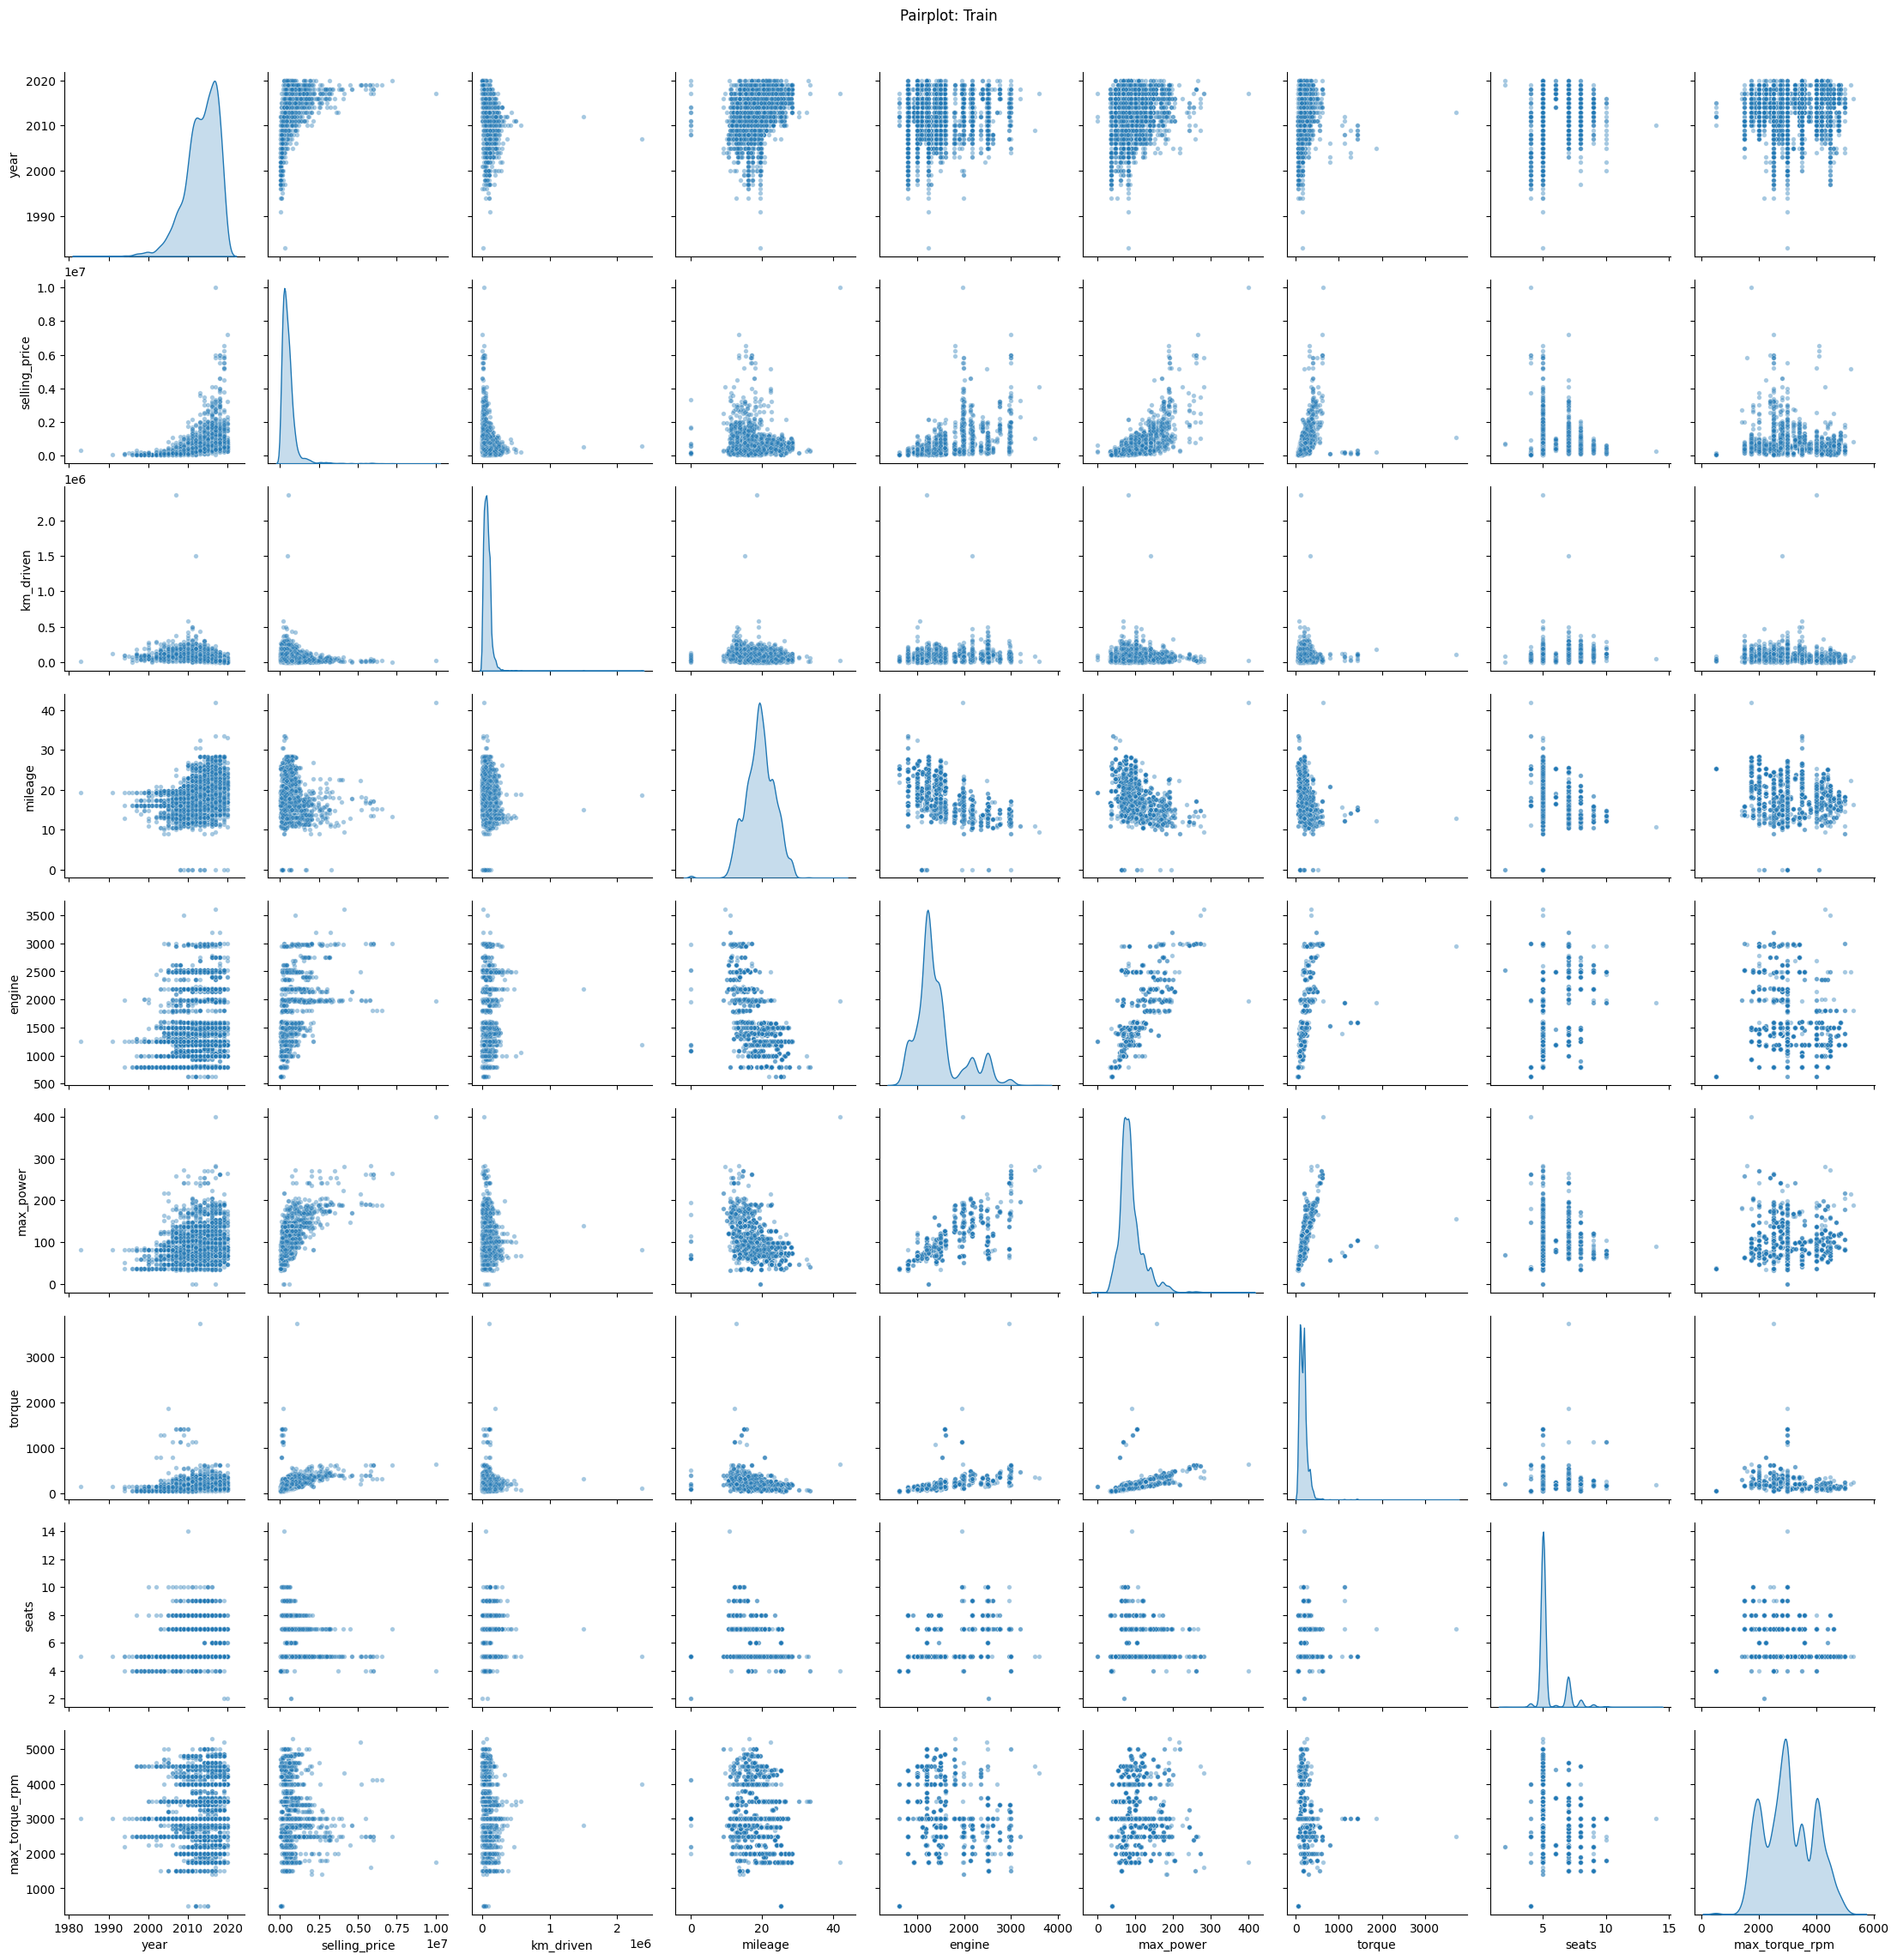

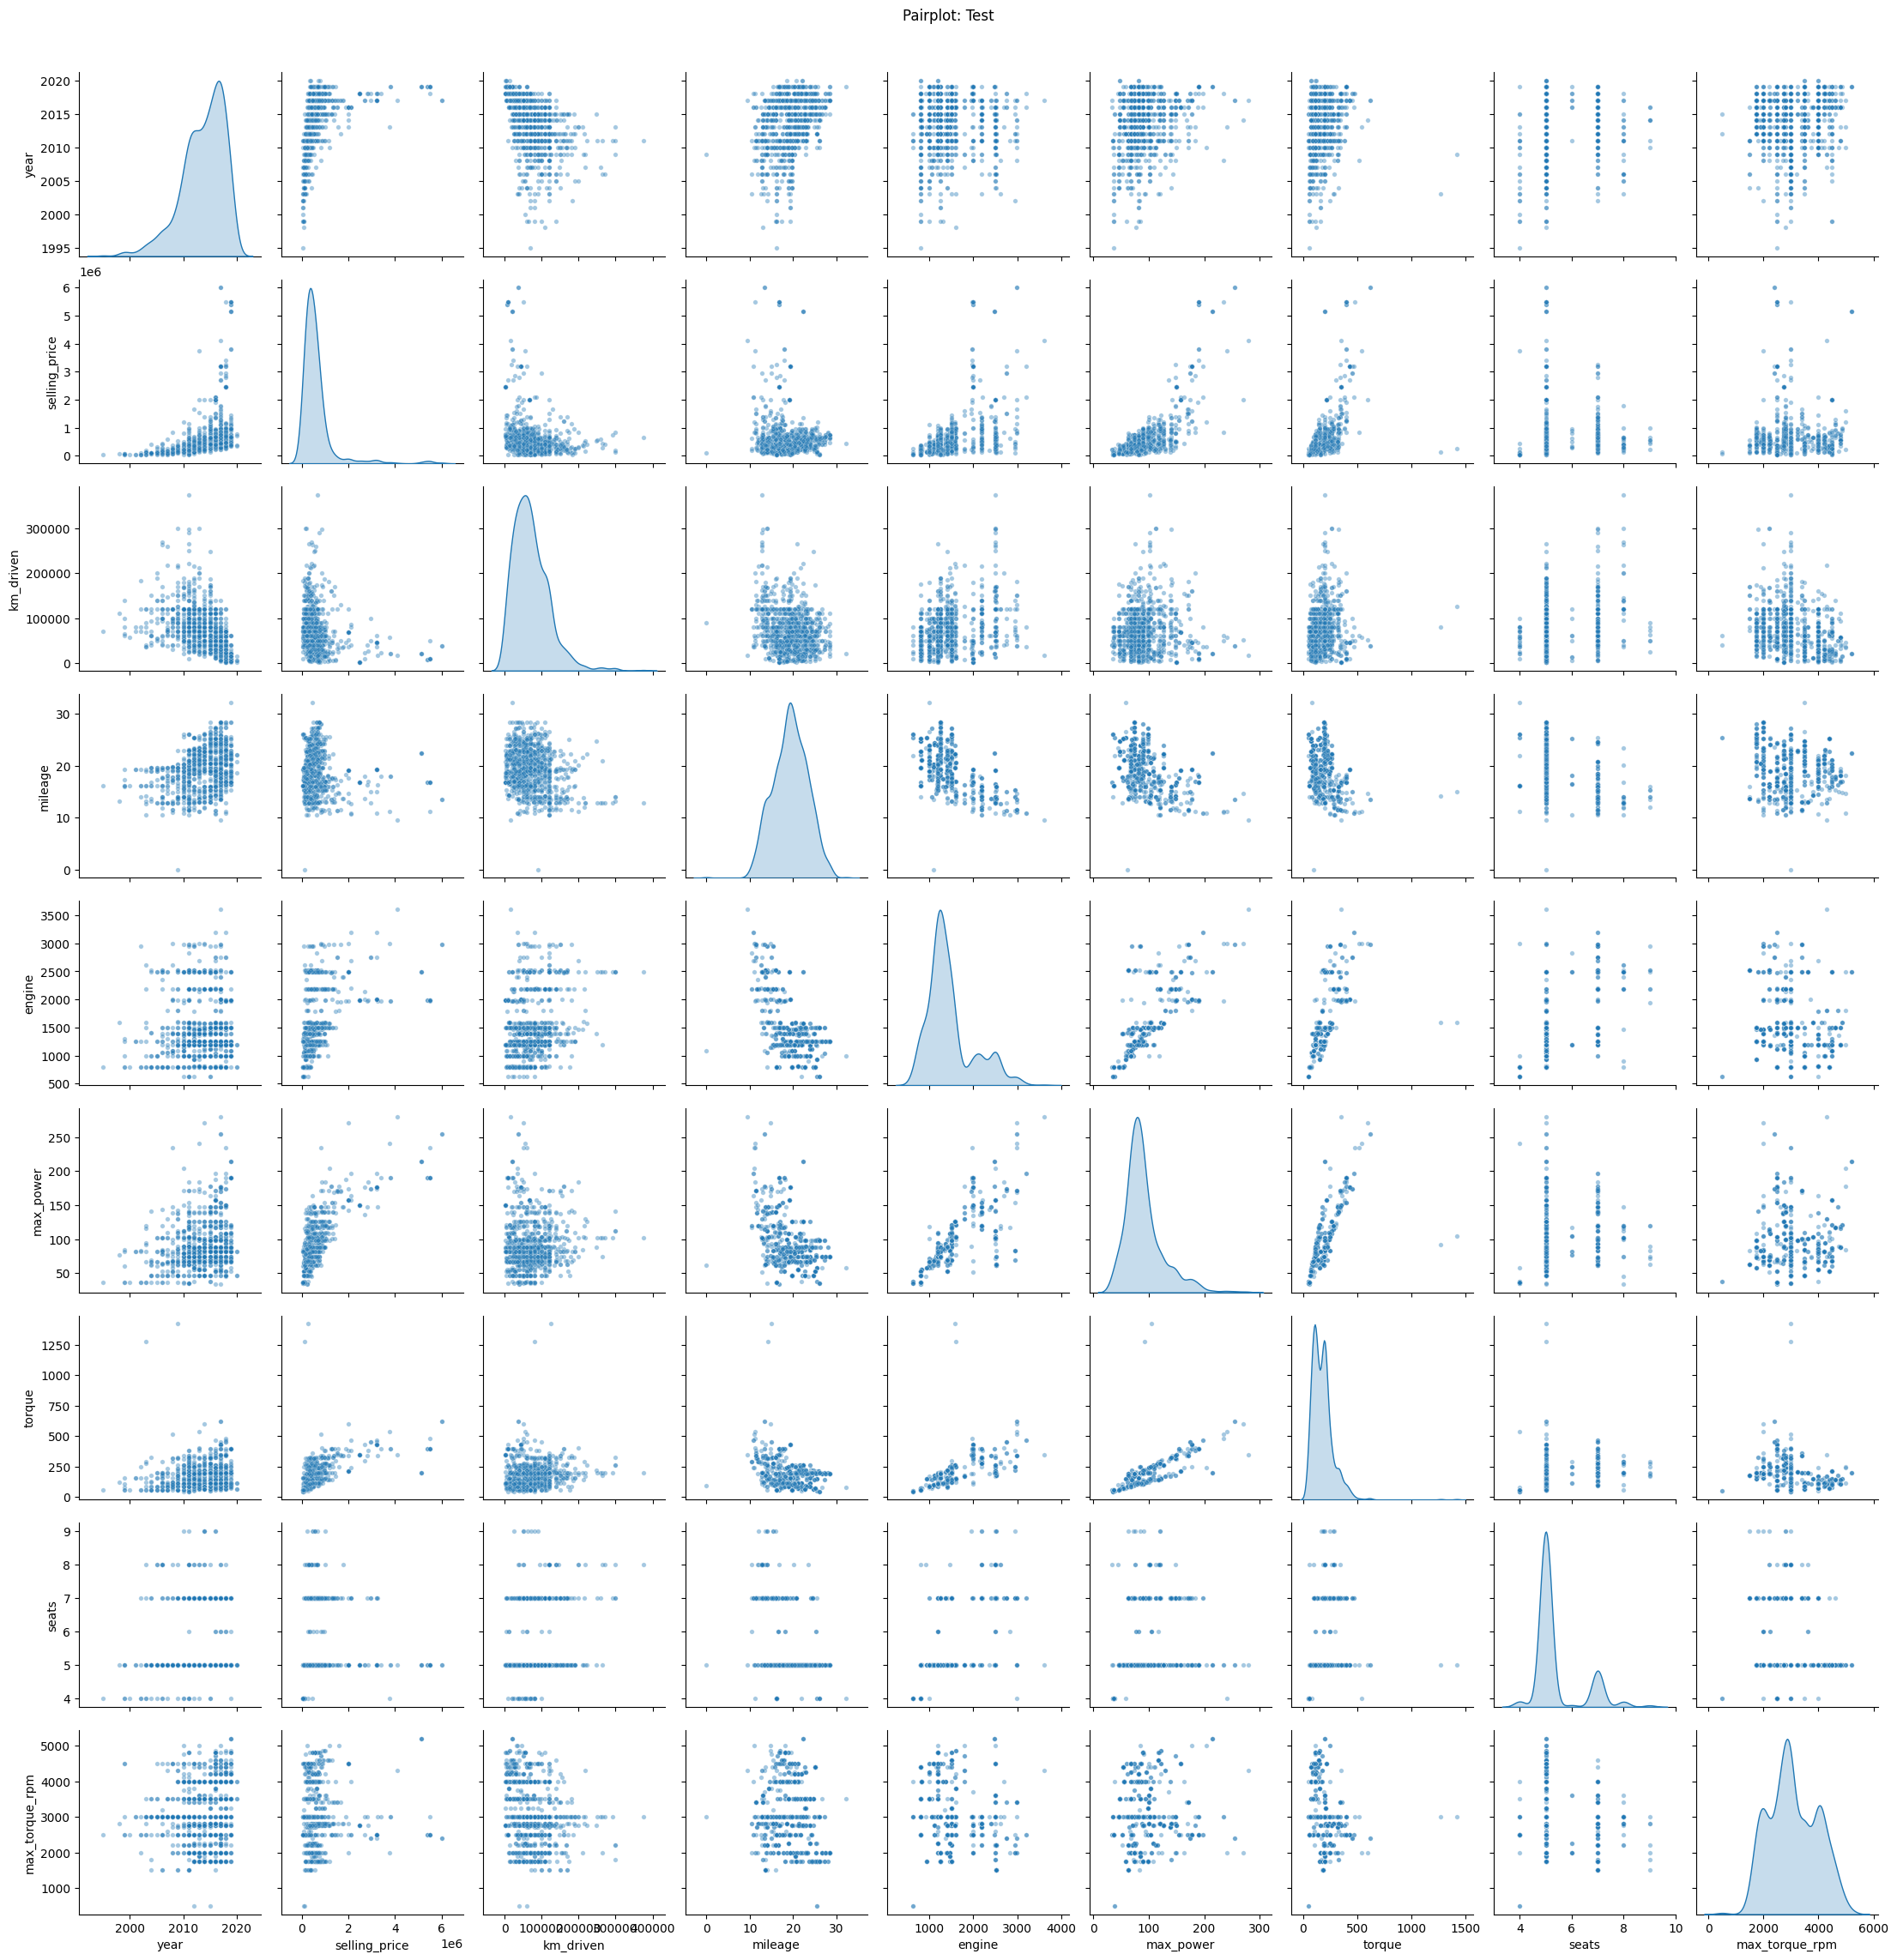

In [17]:
g_train = sns.pairplot(df_train, diag_kind='kde', plot_kws={'alpha': 0.4, 's': 15})
g_train.figure.suptitle("Pairplot: Train", y=1.02)
display(g_train.figure)
plt.close(g_train.figure)

g_test = sns.pairplot(df_test, diag_kind='kde', plot_kws={'alpha': 0.4, 's': 15})
g_test.figure.suptitle("Pairplot: Test", y=1.02)
display(g_test.figure)
plt.close(g_test.figure)

Смотря на графики и анализируя корреляции в профиле, можно сделать вывод о том, что признаки характеристик двигателя имеют прямую положительную корреляцию с таргетной переменной. В частности, сильная связь видна между ценой и максимальной мощностью (max_power), крутящим моментом (torque) и объемом двигателя (engine). В целом это логично, так как более премиальные автомобили, как правило, имеют большую мощность. Также видна значимая корреляция таргета с типом трансмиссии и годом выпуска: очевидно, что более новые автомобили дороже, а автоматическую коробку передач чаще ставят на более дорогие комплектации и модели. Кроме того, у пробега (km_driven) и расхода топлива (mileage) прослеживается отрицательная связь с ценой, так как машины с большим пробегом дешевле, а мощные дорогие автомобили потребляют больше топлива.
Что касается корреляций признаков между собой, можно заметить сильную положительную корреляцию между engine, max_power и torque, так как все эти параметры характеризуют силовую установку автомобиля и физически связаны между собой. Это важно учитывать при построении линейных моделей из за риска мультиколлинеарности. Также заметна отрицательная корреляция года выпуска (year) с пробегом (km_driven), что абсолютно логично, ведь чем старше автомобиль, тем больше километров он успел проехать. Дополнительно объем двигателя (engine) связан с количеством мест (seats) и отрицательно связан с расходом топлива (mileage), так как более крупные и вместительные машины требуют более мощного и объемного мотора с повышенным расходом.
Данные на тесте и трейне ведут себя одинаково: формы распределений и взаимосвязи между признаками совпадают, что говорит об однородности выборок и корректном разбиении без сдвига данных (data shift). Это означает, что тестовая и тренировочная выборки валидны, переразбиение данных не требуется, и качество модели на валидации будет адекватно отражать её работу на тесте.

### **Задание 9 (0.2 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
year,1.000000,0.427279,-0.368966,0.341334,0.002819,0.156858,0.048262,0.041178,0.058454
selling_price,0.427279,1.000000,-0.164828,-0.104769,0.447672,0.692814,0.433124,0.149953,-0.089044
km_driven,-0.368966,-0.164828,1.000000,-0.182086,0.229766,0.024588,0.106602,0.192328,-0.213797
mileage,0.341334,-0.104769,-0.182086,1.000000,-0.572893,-0.373390,-0.226219,-0.451059,-0.185519
engine,0.002819,0.447672,0.229766,-0.572893,1.000000,0.681117,0.566066,0.652172,-0.253163
max_power,0.156858,0.692814,0.024588,-0.373390,0.681117,1.000000,0.616197,0.244112,-0.026347
torque,0.048262,0.433124,0.106602,-0.226219,0.566066,0.616197,1.000000,0.298097,-0.320660
seats,0.041178,0.149953,0.192328,-0.451059,0.652172,0.244112,0.298097,1.000000,-0.214508
max_torque_rpm,0.058454,-0.089044,-0.213797,-0.185519,-0.253163,-0.026347,-0.320660,-0.214508,1.000000


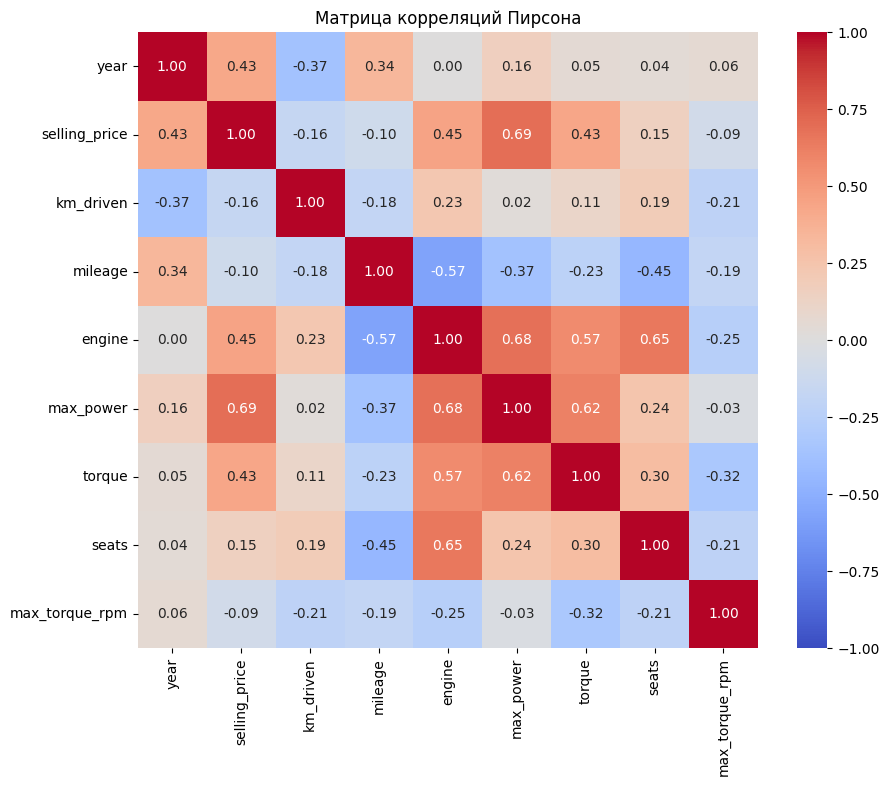

In [18]:
corr_matrix = df_train.corr(numeric_only=True)
display(corr_matrix)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Матрица корреляций Пирсона")
display(fig)
plt.close(fig)


- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?
 - Изучите типы корреляций в `DataFrame.corr()`. Какую вы использовали по умолчанию?

1. Наименее скоррелированы между собой engine и year (коэффициент корреляции близок к нулю), что ожидаемо, так как объем двигателя автомобиля напрямую не связан с годом его выпуска.
2. Довольно сильная положительная линейная зависимость наблюдается между максимальной мощностью и ценой продажи , а также между максимальной мощностью  и объемом двигателя . Первая связь объясняется тем, что более мощные автомобили относятся к более дорогому сегменту, а вторая вытекает из физики работы двигателя.
3. Да, утверждать так правильно: отрицательная корреляция около минус 0.4 между годом выпуска и пробегом  подтверждает, что чем меньше год выпуска (то есть чем старше автомобиль), тем больше километров он, как правило, проехал к дате продажи.
4. По умолчанию в методе DataFrame.corr() используется коэффициент линейной корреляции Пирсона (pearson). Кроме него метод также поддерживает ранговые корреляции Спирмена (spearman) и Кендалла (kendall).


### **Задание 10 (0.35 балла)**

По умолчанию `DataFrame.corr` возвращает корреляцию Пирсона, говорящую о линейной взаимосвязи. Но зависимости существуют не только линейные! В этой задаче, попробуйте другие способы вычисления корреляций.

- [ ] Реализуйте корреляцию Спирмена/Кендалла (на выбор) без использования библиотек (можно пользоваться только `numpy`). Сравните результаты вычисления с библиотечной реализацией
- [ ] Сделайте выводы


Постройте матрицу корреляции [phik](https://pypi.org/project/phik/)
- [ ] Проинтерпретируйте результаты

In [19]:
def rank_average_numpy(arr: np.ndarray) -> np.ndarray:

    n = len(arr)
    sorter = np.argsort(arr)
    
    inv = np.empty(n, dtype=np.intp)
    inv[sorter] = np.arange(n, dtype=np.intp)
    
    arr_sorted = arr[sorter]
    obs = np.r_[True, arr_sorted[1:] != arr_sorted[:-1]]
    dense = obs.cumsum() - 1
    
    count = np.r_[np.nonzero(obs)[0], n]
    
    avg_ranks = 0.5 * (count[dense] + count[dense + 1] + 1)
    return avg_ranks[inv]


def get_spearman_corr(df: pd.DataFrame, col1: str, col2: str) -> float:
    clean_df = df[[col1, col2]].dropna()
    
    arr_1 = clean_df[col1].to_numpy()
    arr_2 = clean_df[col2].to_numpy()
    
    if len(arr_1) < 2:
        return np.nan

    rank_1 = rank_average_numpy(arr_1)
    rank_2 = rank_average_numpy(arr_2)

    r1_diff = rank_1 - np.mean(rank_1)
    r2_diff = rank_2 - np.mean(rank_2)
    
    numerator = np.sum(r1_diff * r2_diff)
    denominator = np.sqrt(np.sum(r1_diff ** 2) * np.sum(r2_diff ** 2))
    
    if denominator == 0:
        return np.nan
        
    return float(numerator / denominator)

In [20]:
import math
my_res_2 = get_spearman_corr(df_train, 'selling_price', 'km_driven')
pd_res_2 = df_train['selling_price'].corr(df_train['km_driven'], method='spearman')
print(math.isclose(my_res_2, pd_res_2)) 

True


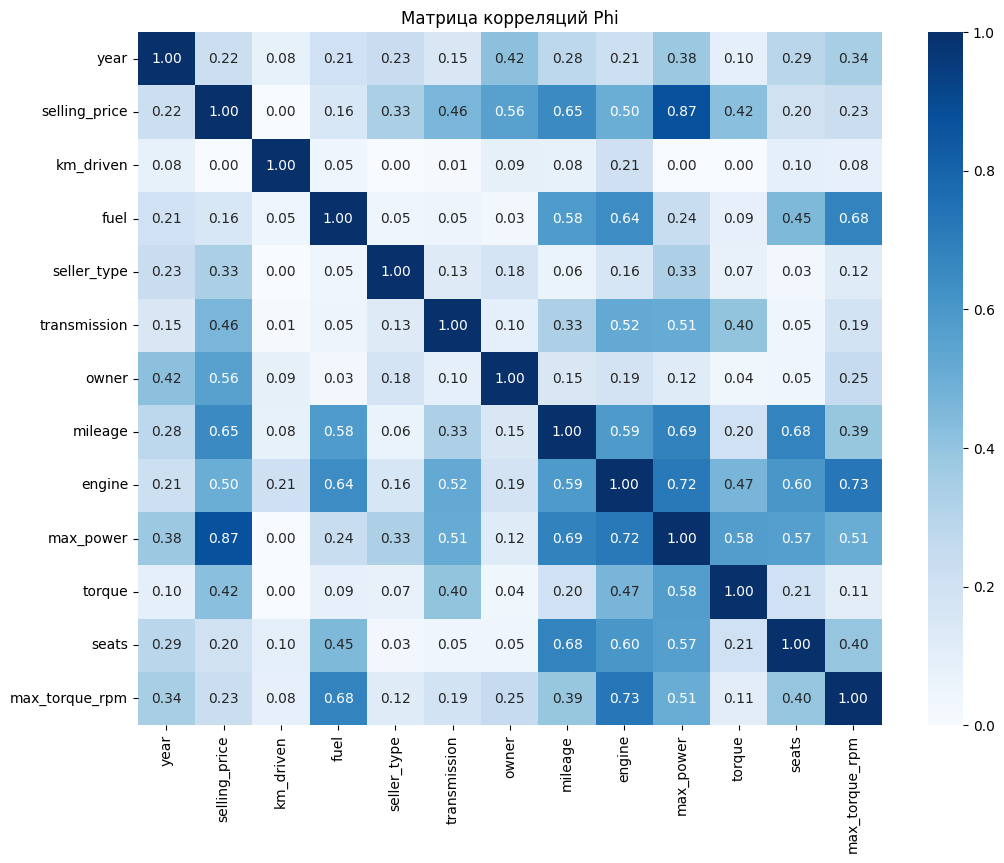

In [21]:
import phik

cols_for_phik = [col for col in df_train.columns if col != 'name']
phik_matrix = df_train[cols_for_phik].phik_matrix(interval_cols=df_train[cols_for_phik].select_dtypes(include='number').columns.tolist())

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(phik_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Матрица корреляций Phi")
display(fig)
plt.close(fig)

Изначально у меня не сошлись спирмен так как я считал по формуле $$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$ о она применима только при отсутствии повторяющихся значений (связанных рангов). В наших данных много одинаковых значений , поэтому корректный коэффициент Спирмена вычисляется как коэффициент корреляции Пирсона между усреднёнными рангами переменных.


По матрице корреляций Phi_K наиболее сильная связь с ценой продажи selling_price наблюдается у максимальной мощности max_power (0.87), расхода топлива mileage (0.65), количества владельцев owner (0.56), объема двигателя engine (0.50) и типа трансмиссии transmission (0.46). В отличие от Пирсона, Phi_K выявил высокую значимость категориальных признаков (особенно owner и transmission) и показал сильную нелинейную связь цены с расходом mileage. Нулевые значения у пробега km_driven объясняются экстремальными выбросами свыше 2 млн км, из за которых при автоматическом разбиении на интервалы почти все обычные авто попали в один бин. Среди самих признаков ожидаемо сильно связаны характеристики двигателя и топлива (engine и max_torque_rpm 0.73, engine и max_power 0.72, fuel и max_torque_rpm 0.68), расход и число мест (mileage и seats 0.68), а также год выпуска и число владельцев (year и owner 0.42).

### **Задание 11 (0.1 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

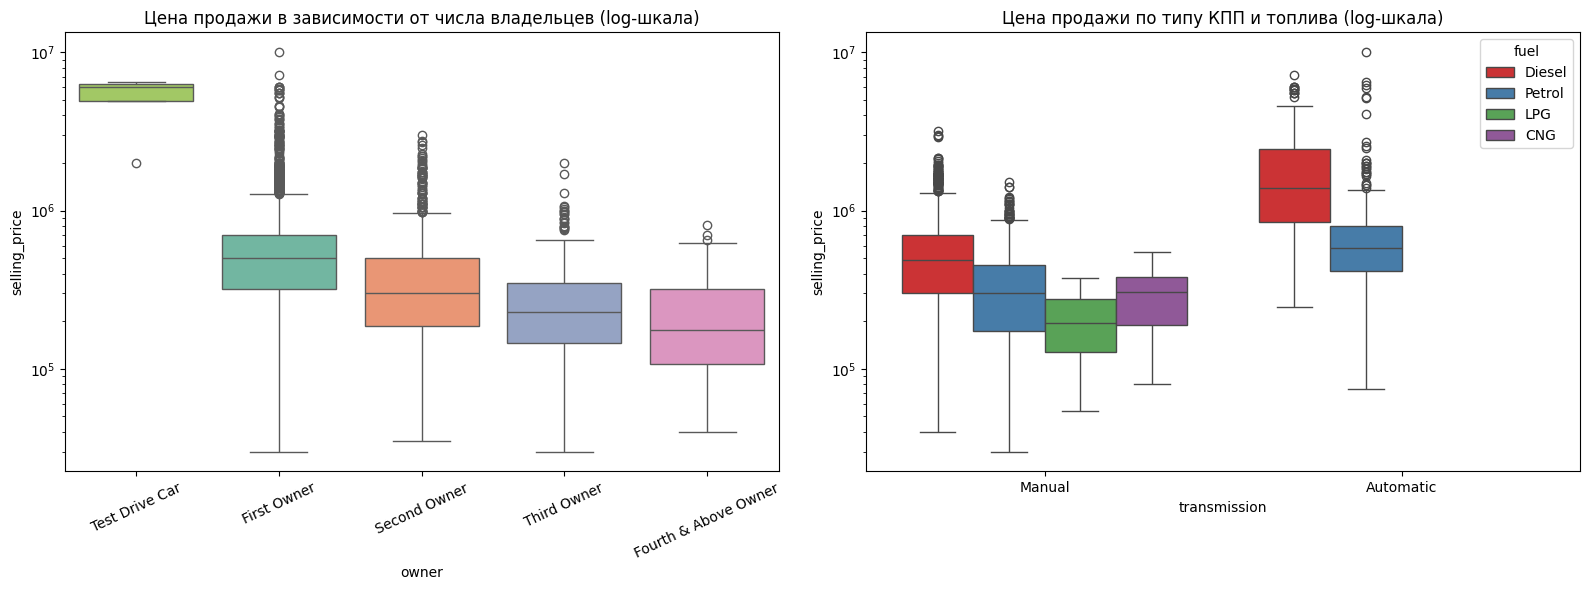

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

owner_order = ['Test Drive Car', 'First Owner', 'Second Owner', 'Third Owner', 'Fourth & Above Owner']
sns.boxplot(data=df_train, x='owner', y='selling_price', order=owner_order, hue='owner', palette='Set2', legend=False, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Цена продажи в зависимости от числа владельцев (log-шкала)')
axes[0].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_train, x='transmission', y='selling_price', hue='fuel', palette='Set1', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Цена продажи по типу КПП и топлива (log-шкала)')

plt.tight_layout()
display(fig)
plt.close(fig)

Наглядно видно что фик кожфициент верно подсветил связь цены продажи и количетсва владельцов она прям прослеживается то есть это очень важная фича. Также видна явная зависимость в случае с коробкой передач. Делаем вывод что очень важно отслеживать категориальные признаки и смотреть их коореляцию.

# **Часть 2 (1.4 балла) | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.4 балла.

### **Задание 12 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [23]:
target = "selling_price"
cat_cols = ["owner", "name", "fuel", "seller_type", "transmission"]

df_train_num = df_train.drop(columns=cat_cols).copy()
df_test_num = df_test.drop(columns=cat_cols).copy()

y_train = df_train_num[target]
X_train = df_train_num.drop(columns=[target])

y_test = df_test_num[target]
X_test = df_test_num.drop(columns=[target])

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(5840, 8) (5840,) (1000, 8) (1000,)


In [24]:
X_train.dtypes

year                int64
km_driven           int64
mileage           float64
engine              int64
max_power         float64
torque            float64
seats               int64
max_torque_rpm    float64
dtype: object

### **Задание 13 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [25]:
model = LinearRegression()
model.fit(X_train,y_train)
pred_test= model.predict(X_test)
pred_train =  model.predict(X_train)
print(f"R2 train score is {r2_score(y_train,pred_train)}")
print(f"MSE train score is {MSE(y_train,pred_train)}")

print(f"R2 test score is {r2_score(y_test,pred_test)}")
print(f"MSE test score is {MSE(y_test,pred_test)}")

R2 train score is 0.6013052515059976
MSE train score is 114281200220.33635
R2 test score is 0.600571141023624
MSE test score is 229603114085.70212


Модель пока слабая, так как R2 составляет около 0.60, то есть она объясняет лишь около 60 процентов дисперсии цены. Это уже лучше константного предсказания, но недостаточно для реального применения, хотя в качестве простого бейзлайна такой результат подходит. Также видно, что переобучения (оверфита) вообще нет, так как R2 на тренировочной (0.601) и тестовой (0.601) выборках практически совпадают, а более высокий MSE на тесте (2.30e11 против 1.14e11 на трейне) объясняется большей дисперсией целевой переменной в тестовой выборке (мы это смотрели когда распределение selling price видели ) и высокой чувствительностью MSE к крупным ошибкам на дорогих автомобилях.

### **Задание 14 (0.25 балла)**

**Шаг 1 (0.15 балла)**
- [ ] Реализуйте $R^2$ руками. Приведите формулу $R^2$ и объясните каждую компоненту метрики

In [26]:
def get_r2_score(y_true : pd.DataFrame,y_pred: pd.DataFrame) -> float:
    sse = ((y_true - y_pred)**2).sum() # сумма квадратов ошибок
    div = ((y_true - y_true.mean())**2).sum() # дисперсия исходной переменной
    return 1 - sse/div

Функция считает R² так: сначала sse находит сумму квадратов всех ошибок модели . Затем div считает общий разброс самих данных вокруг их среднего значения. Деление sse на div показывает, какую долю этого базового разброса модель не смогла объяснить. Вычитая эту долю из единицы, мы получаем финальный R² процент разброса данных, который модель успешно уловила.

**Шаг 2 (0.1 балла)**

- [ ] Реализуйте [$\text{adjusted}-R^2$](https://en.wikipedia.org/wiki/Coefficient_of_determination).
- [ ] Объясните, когда применяется $\text{adjusted}-R^2$?

In [27]:
def get_r2_score_adjusted(y_true : pd.DataFrame,y_pred: pd.DataFrame, p) -> float:
    r2 = get_r2_score(y_true,y_pred)
    n = y_true.shape[0]
    return 1 - (1 - r2)*(n - 1)/(n - p - 1)

Классический коэффициент детерминации имеет существенный недостаток: при добавлении новых признаков в модель его значение всегда растет (или как минимум не уменьшается), даже если эти признаки являются случайным шумом и не несут реальной пользы. Из-за этого по обычному R² нельзя корректно сравнивать модели с разным количеством факторов.
Для объективного выбора лучшей модели используется скорректированный R² . Эта метрика вводит штраф за сложность модели (количество признаков относительно объема выборки): она растет только в том случае, если новый признак действительно улучшает качество прогноза сильнее, чем это ожидалось бы от случайного совпадения.


### **Задание 15 (0.05 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [28]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled,y_train)
pred_test= model.predict(X_test_scaled)
pred_train =  model.predict(X_train_scaled)
print(f"R2 train score is {r2_score(y_train,pred_train)}")
print(f"MSE train score is {MSE(y_train,pred_train)}")

print(f"R2 test score is {r2_score(y_test,pred_test)}")
print(f"MSE test score is {MSE(y_test,pred_test)}")

R2 train score is 0.6013052515059962
MSE train score is 114281200220.33673
R2 test score is 0.6005711410236432
MSE test score is 229603114085.69107


### **Задание 16 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

,Признак,Вес (coef),Важность (|coef|)
4,max_power,334460.321036,334460.321036
0,year,166669.087800,166669.087800
7,max_torque_rpm,-62917.617921,62917.617921
1,km_driven,-49274.738877,49274.738877
6,seats,-30806.315530,30806.315530
3,engine,22814.999631,22814.999631
2,mileage,-10298.455194,10298.455194
5,torque,-3232.251937,3232.251937


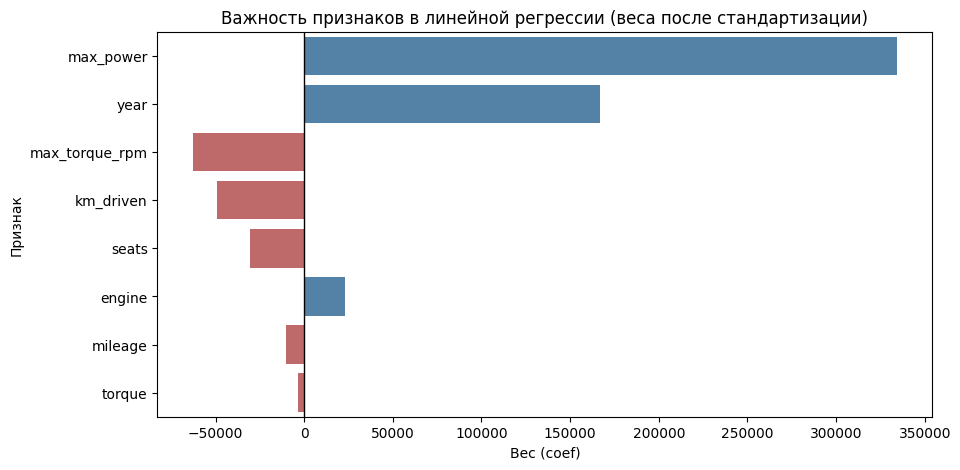

Наиболее информативный признак: max_power


In [29]:
coef_df = pd.DataFrame({
    'Признак': X_train.columns,
    'Вес (coef)': model.coef_,
    'Важность (|coef|)': np.abs(model.coef_)
}).sort_values(by='Важность (|coef|)', ascending=False)

display(coef_df)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['steelblue' if c > 0 else 'indianred' for c in coef_df['Вес (coef)']]
sns.barplot(data=coef_df, x='Вес (coef)', y='Признак', hue='Признак', palette=colors, legend=False, ax=ax)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Важность признаков в линейной регрессии (веса после стандартизации)')
display(fig)
plt.close(fig)

print("Наиболее информативный признак:", coef_df.iloc[0]['Признак'])


### **Задание 17 (0.2 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [30]:
model = Lasso()
model.fit(X_train_scaled,y_train)
pred_test= model.predict(X_test_scaled)
pred_train =  model.predict(X_train_scaled)
print(f"R2 train score is {r2_score(y_train,pred_train)}")
print(f"MSE train score is {MSE(y_train,pred_train)}")

print(f"R2 test score is {r2_score(y_test,pred_test)}")
print(f"MSE test score is {MSE(y_test,pred_test)}")

R2 train score is 0.6013052514353792
MSE train score is 114281200240.57828
R2 test score is 0.6005697869719677
MSE test score is 229603892433.25992


In [31]:
X_train_scaled

array([[ 0.13956959,  1.19115249,  0.995867  , ...,  0.12051229,
        -0.43441899, -1.20397156],
       [ 0.13956959,  0.76661943,  0.42883018, ...,  0.63444143,
        -0.43441899, -0.62506359],
       [-0.83716668,  0.88315792,  0.8955065 , ...,  0.37464134,
        -0.43441899, -0.3356096 ],
       ...,
       [-0.10461448,  0.60013588, -0.2335491 , ..., -0.53303428,
        -0.43441899,  1.11166032],
       [-1.56971888,  0.74997108, -0.66008122, ...,  0.5090393 ,
        -0.43441899, -0.04615562],
       [-1.08135075,  0.76661943, -0.03282811, ...,  0.12051229,
        -0.43441899, -1.20397156]], shape=(5840, 8))

,Признак,Вес (coef),Важность (|coef|)
4,max_power,334459.541455,334459.541455
0,year,166666.951103,166666.951103
7,max_torque_rpm,-62914.370002,62914.370002
1,km_driven,-49273.753939,49273.753939
6,seats,-30802.461587,30802.461587
3,engine,22812.484882,22812.484882
2,mileage,-10295.163349,10295.163349
5,torque,-3228.721032,3228.721032


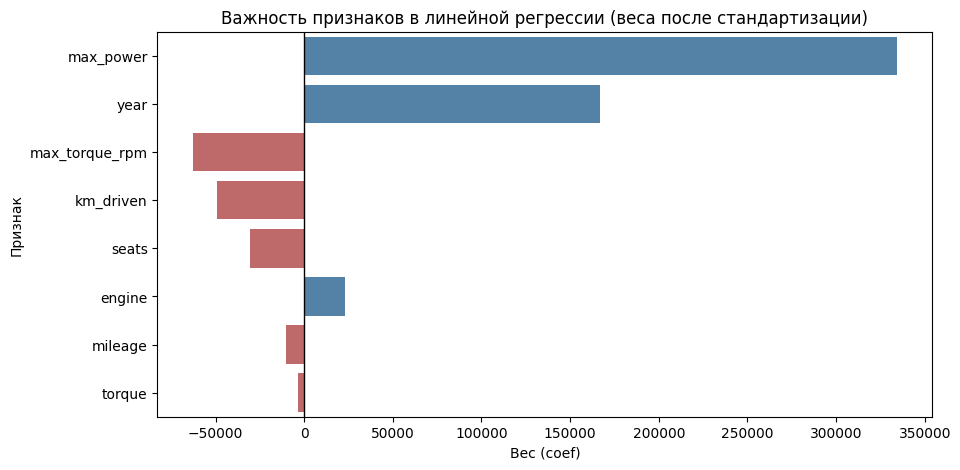

Наиболее информативный признак: max_power


In [32]:
coef_df = pd.DataFrame({
    'Признак': X_train.columns,
    'Вес (coef)': model.coef_,
    'Важность (|coef|)': np.abs(model.coef_)
}).sort_values(by='Важность (|coef|)', ascending=False)

display(coef_df)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['steelblue' if c > 0 else 'indianred' for c in coef_df['Вес (coef)']]
sns.barplot(data=coef_df, x='Вес (coef)', y='Признак', hue='Признак', palette=colors, legend=False, ax=ax)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Важность признаков в линейной регрессии (веса после стандартизации)')
display(fig)
plt.close(fig)

print("Наиболее информативный признак:", coef_df.iloc[0]['Признак'])


Ничего не изменилось. Причина в том, что после стандартизации веса составили максимум около 350 тысяч, что несоизмеримо меньше самой ошибки MSE, которая достигает 11 степени. То есть при таком малом значении альфа штраф регуляризации почти не влияет на функцию потерь, так как целевая переменная слишком велика. Кроме того, признаков мало, все они действительно могут быть важными, а сама модель изначально не переобучена.

### **Задание 18. Финальный рывок (0.3 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Что значит каждый параметр `param_grid`, который вы заполняли для `GridSearch`? Опишите каждый
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [33]:
param_grid = {
    'alpha': np.logspace(0, 5, 50)
}

grid_lasso = GridSearchCV(
    estimator=Lasso(max_iter=10000, random_state=42),
    param_grid=param_grid,
    cv=10,
    scoring='r2',
    n_jobs=-1
)

grid_lasso.fit(X_train_scaled, y_train)
p_nonzero = np.sum(grid_lasso.best_estimator_.coef_ != 0)

print("Лучший alpha:", grid_lasso.best_params_['alpha'])
print("Лучший R2 на кросс-валидации:", grid_lasso.best_score_)

y_pred_train = grid_lasso.predict(X_train_scaled)
y_pred_test = grid_lasso.predict(X_test_scaled)

print("R2 train:", r2_score(y_train, y_pred_train))
print("R2 test:", r2_score(y_test, y_pred_test))
print("R2 train adjusted:", get_r2_score_adjusted(y_train, y_pred_train, p_nonzero))
print("R2 test adjusted:", get_r2_score_adjusted(y_test, y_pred_test, p_nonzero))
print("MSE test:", MSE(y_test, y_pred_test))

best_coefs = pd.Series(grid_lasso.best_estimator_.coef_, index=X_train.columns)
display(best_coefs)

Лучший alpha: 19306.977288832495
Лучший R2 на кросс-валидации: 0.5834276808664216
R2 train: 0.5948224732735762
R2 test: 0.5766947993776987
R2 train adjusted: 0.594544716614295
R2 test adjusted: 0.5749930699279608
MSE test: 243327917067.95932


year              149184.951374
km_driven         -29385.655895
mileage                0.000000
engine                 0.000000
max_power         328022.716192
torque                 0.000000
seats                 -0.000000
max_torque_rpm    -34726.680713
dtype: float64

,Признак,Вес (coef),Важность (|coef|)
4,max_power,328022.716192,328022.716192
0,year,149184.951374,149184.951374
7,max_torque_rpm,-34726.680713,34726.680713
1,km_driven,-29385.655895,29385.655895
3,engine,0.000000,0.000000
2,mileage,0.000000,0.000000
5,torque,0.000000,0.000000
6,seats,-0.000000,0.000000


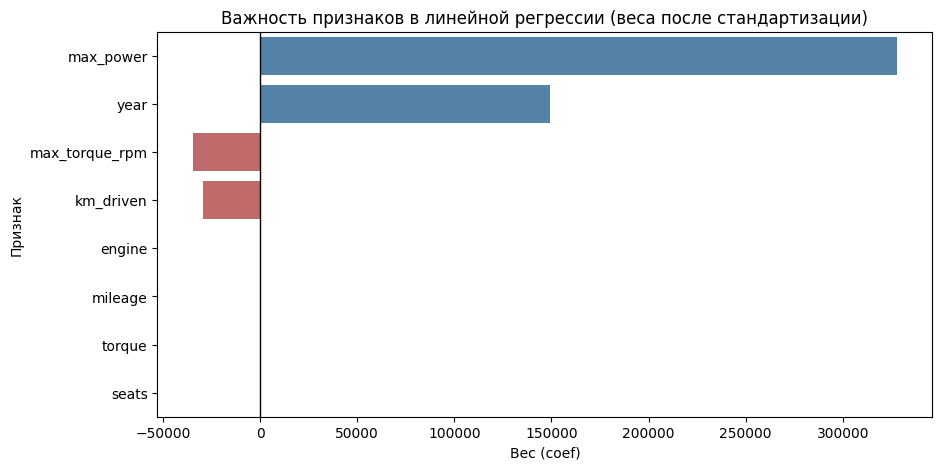

Наиболее информативный признак: max_power


In [34]:
coef_df = pd.DataFrame({
    'Признак': X_train.columns,
    'Вес (coef)': grid_lasso.best_estimator_.coef_,
    'Важность (|coef|)': np.abs(grid_lasso.best_estimator_.coef_)
}).sort_values(by='Важность (|coef|)', ascending=False)

display(coef_df)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['steelblue' if c > 0 else 'indianred' for c in coef_df['Вес (coef)']]
sns.barplot(data=coef_df, x='Вес (coef)', y='Признак', hue='Признак', palette=colors, legend=False, ax=ax)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('Важность признаков в линейной регрессии (веса после стандартизации)')
display(fig)
plt.close(fig)

print("Наиболее информативный признак:", coef_df.iloc[0]['Признак'])


Обучался он недолго, 1.5 секунды, но это значительно дольше, чем обычное обучение (что логично), и в асимптотике время работы зависит от количества фолдов (k folds) и размера сетки параметров. Точно сравнить скорость сложно, так как она зависит от железа.
Параметры GridSearchCV:
estimator это экземпляр самой модели, которую мы обучаем.
param_grid это сетка гиперпараметров модели, которые мы перебираем.
cv это количество фолдов в эксперименте.
n_jobs это количество параллельных процессов (так как библиотека написана на C/Cython, вычисления хорошо распараллеливаются).
scoring это метрика, по которой алгоритм оценивает качество и ищет лучшую модель.
Лучший альфа оказался огромным: 19306.98. При таком штрафе занулились веса всех признаков, кроме max_power, year, max_torque_rpm и km_driven, то есть остались только ключевые факторы.

**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [35]:
param_grid = {
    'alpha': np.logspace(-2, 4, 25),
    'l1_ratio': np.linspace(0.05, 1.0, 20)
}

grid_elastic = GridSearchCV(
    estimator=ElasticNet(max_iter=10000, random_state=42),
    param_grid=param_grid,
    cv=10,
    scoring='r2',
    n_jobs=-1
)

grid_elastic.fit(X_train_scaled, y_train)

n_candidates = len(grid_elastic.cv_results_['params'])
n_fits = n_candidates * grid_elastic.n_splits_ + (1 if grid_elastic.refit else 0)

print("Комбинаций параметров:", n_candidates)
print("Всего обучено моделей (с учётом refit):", n_fits)
print("Лучшие гиперпараметры:", grid_elastic.best_params_)
print("Лучший R2 на кросс-валидации:", grid_elastic.best_score_)

y_pred_train = grid_elastic.predict(X_train_scaled)
y_pred_test = grid_elastic.predict(X_test_scaled)

p_nonzero = np.sum(grid_elastic.best_estimator_.coef_ != 0)
print("Ненулевых признаков:", p_nonzero)
print("R2 train adjusted:", get_r2_score_adjusted(y_train, y_pred_train, p_nonzero))
print("R2 test adjusted:", get_r2_score_adjusted(y_test, y_pred_test, p_nonzero))
print("MSE test:", MSE(y_test, y_pred_test))

best_coefs = pd.Series(grid_elastic.best_estimator_.coef_, index=X_train.columns)
display(best_coefs)

Комбинаций параметров: 500
Всего обучено моделей (с учётом refit): 5001
Лучшие гиперпараметры: {'alpha': np.float64(1.0), 'l1_ratio': np.float64(0.9)}
Лучший R2 на кросс-валидации: 0.5810323905400645
Ненулевых признаков: 8
R2 train adjusted: 0.5949677124581847
R2 test adjusted: 0.573763954614738
MSE test: 243050587063.94788


year              154091.426576
km_driven         -51017.705637
mileage             -756.452450
engine             54867.952634
max_power         275546.644760
torque             22728.267574
seats             -32201.669242
max_torque_rpm    -41996.633269
dtype: float64

Обучение происходило долго, около 20 секунд, так как сетка содержала много комбинаций гиперпараметров. Всего грид серчу пришлось обучить 5001 модель: 500 комбинаций параметров на 10 фолдах кросс валидации (5000 обучений) плюс 1 финальное дообучение лучшей модели на всей тренировочной выборке. Лучшими гиперпараметрами оказались alpha = 1.0 и l1_ratio = 0.9.

### **Задание 19 (0.25 балла)**

Итак, вы обучили все варианты регуляризаций, доступные в sklearn, но не все, что мы обсудили на занятии! Следующее задание — о забытой $L0$-регуляризации.

Задача линейной регрессии с $L0$-регуляризацией:

$$\min_{w}\; \frac{1}{n}\|y - Xw\|_2^2 + \lambda \|w\|_0, \qquad \|w\|_0 = \#\{j : w_j \neq 0\}.$$

Штраф $\|w\|_0$ разрывный и невыпуклый, поэтому градиентным спуском «в лоб» задачу не решить. **Выберите один** из способов (или предложите свой и обоснуйте его):

1. **Полный перебор подмножеств (best subset selection).** Для каждого подмножества признаков $S$ обучите МНК только на признаках из $S$ (веса $\hat w_S$) и выберите
$$S^* = \arg\min_{S}\; \frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|.$$
Перебор $2^d$ подмножеств реален при небольшом числе признаков $d$ (у нас вещественных признаков меньше десяти).

2. **Жадный отбор (forward / backward stepwise).** Начните с пустого (полного) набора признаков и на каждом шаге добавляйте (удаляйте) тот признак, который сильнее всего уменьшает $\frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|$. Остановитесь, когда функционал перестанет уменьшаться.

3. **Iterative Hard Thresholding (проксимальный градиентный спуск).** Сделайте шаг градиентного спуска по MSE с шагом $\eta$, затем занулите малые веса:
$$z = w^{(t)} - \eta\, \nabla_w \tfrac{1}{n}\|y - Xw^{(t)}\|_2^2, \qquad w^{(t+1)}_j = z_j \cdot \mathbb{1}\left[|z_j| > \sqrt{2\eta\lambda}\right].$$

4. **Стохастические «ворота» с hard concrete распределением** ([Louizos et al., 2018](https://arxiv.org/abs/1712.01312)). Веса параметризуются как $w = \tilde w \odot z$, где $z_j \in [0, 1]$:
$$u_j \sim U(0,1),\quad s_j = \sigma\!\left(\frac{\log u_j - \log(1-u_j) + \log\alpha_j}{\beta}\right),\quad z_j = \min\big(1, \max(0,\, s_j(\zeta-\gamma)+\gamma)\big),$$
а недифференцируемый $\|w\|_0$ заменяется на его матожидание $\sum_j P(z_j \neq 0)$:
$$\min_{\tilde w,\, \log\alpha}\; \mathbb{E}_u\!\left[\frac{1}{n}\|y - X(\tilde w \odot z)\|_2^2\right] + \lambda\sum_{j}\sigma\!\left(\log\alpha_j - \beta\log\frac{-\gamma}{\zeta}\right).$$
Типичные значения: $\beta = \frac{2}{3},\ \gamma = -0.1,\ \zeta = 1.1$. Оптимизируйте градиентным спуском (например, в PyTorch). На инференсе используйте детерминированные ворота $z_j = \min\big(1, \max(0,\, \sigma(\log\alpha_j)(\zeta-\gamma)+\gamma)\big)$.

Для способов 3 и 4 признаки должны быть стандартизованы.

**Ваша задача:**
- [ ] Реализуйте модель с $L0$-регуляризацией одним из способов выше.
- [ ] Обучите модель при нескольких значениях $\lambda$ и проанализируйте, как меняются число ненулевых весов и качество ($R^2$ и $MSE$ на трейне и тесте).

**Важно:**

Несмотря на то что L0 не реализована в стандартных пакетах, концепция данной регуляризации не является мертвой. Она встречается в статьях и экспериментах.

In [36]:
y_train_np = np.asarray(y_train).ravel()
X_train_np = np.asarray(X_train_scaled)
y_test_np = np.asarray(y_test).ravel()
X_test_np = np.asarray(X_test_scaled)

def grad(w, b):
    n = X_train_np.shape[0]
    error = (X_train_np @ w + b) - y_train_np
    grad_w = (2 / n) * (X_train_np.T @ error)
    grad_b = (2 / n) * np.sum(error)
    return grad_w, grad_b

def gradient_descent(n_steps, step, l):
    n_features = X_train_np.shape[1]
    w = np.random.normal(loc=0.0, scale=0.01, size=n_features)
    b = 0.0
    for _ in range(n_steps):
        gr_w, gr_b = grad(w, b)
        w = w - step * gr_w
        b = b - step * gr_b
        w = np.where(np.abs(w) > np.sqrt(2 * step * l), w, 0)
    return w, b

for l in [0, 1e8, 5e8, 1e9, 3e9, 1e10, 5e10]:
    w, b = gradient_descent(n_steps=2000, step=0.05, l=l)
    y_pred_train = X_train_np @ w + b
    y_pred_test = X_test_np @ w + b
    
    print(f"lambda={l:.0e} | non-zero={np.sum(w != 0)} | "
          f"R2_train={r2_score(y_train_np, y_pred_train):.4f} | R2_test={r2_score(y_test_np, y_pred_test):.4f} | "
          f"MSE_test={MSE(y_test_np, y_pred_test):.2e}")

lambda=0e+00 | non-zero=8 | R2_train=0.6013 | R2_test=0.6006 | MSE_test=2.30e+11
lambda=1e+08 | non-zero=6 | R2_train=0.6011 | R2_test=0.6003 | MSE_test=2.30e+11
lambda=5e+08 | non-zero=5 | R2_train=0.5901 | R2_test=0.5897 | MSE_test=2.36e+11
lambda=1e+09 | non-zero=3 | R2_train=0.5848 | R2_test=0.5809 | MSE_test=2.41e+11
lambda=3e+09 | non-zero=3 | R2_train=0.5848 | R2_test=0.5809 | MSE_test=2.41e+11
lambda=1e+10 | non-zero=1 | R2_train=0.4800 | R2_test=0.5128 | MSE_test=2.80e+11
lambda=5e+10 | non-zero=0 | R2_train=0.0000 | R2_test=-0.0157 | MSE_test=5.84e+11


В целом всё логично. Чем жёстче критерий лямбда мы ставим, тем больше слабых весов зануляется при обучении, и таким образом мы выделяем самые ценные переменные (происходит автоматический отбор признаков). Метрики закономерно падают, так как мы теряем часть информации, но происходит это не сразу: при умеренном штрафе (lambda = 1e+08) модель отбрасывает 2 наименее значимых признака (остаётся 6), а качество на тесте практически не меняется (R2_test = 0.6003 против 0.6006 при том же MSE_test = 2.30e+11), так как эти признаки дублировали информацию других характеристик. При дальнейшем росте штрафа до lambda = 1e+09 остаётся всего 3 ключевых признака при небольшом снижении R2_test до 0.5809, а при слишком большом штрафе (lambda = 5e+10) обнуляются все веса и модель вырождается в константное предсказание среднего значения цены (R2_train = 0.0000, R2_test = -0.0157, MSE_test = 5.84e+11).

# **Часть 3 (0.5 балла) | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.5 балла.

### **Задание 20 (0.1 балла)**

Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Предобработайте столбец `name`, чтобы избежать его удаления

/tmp/ipykernel_10756/42292757.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_cats.values, y=top_cats.index, palette='viridis')


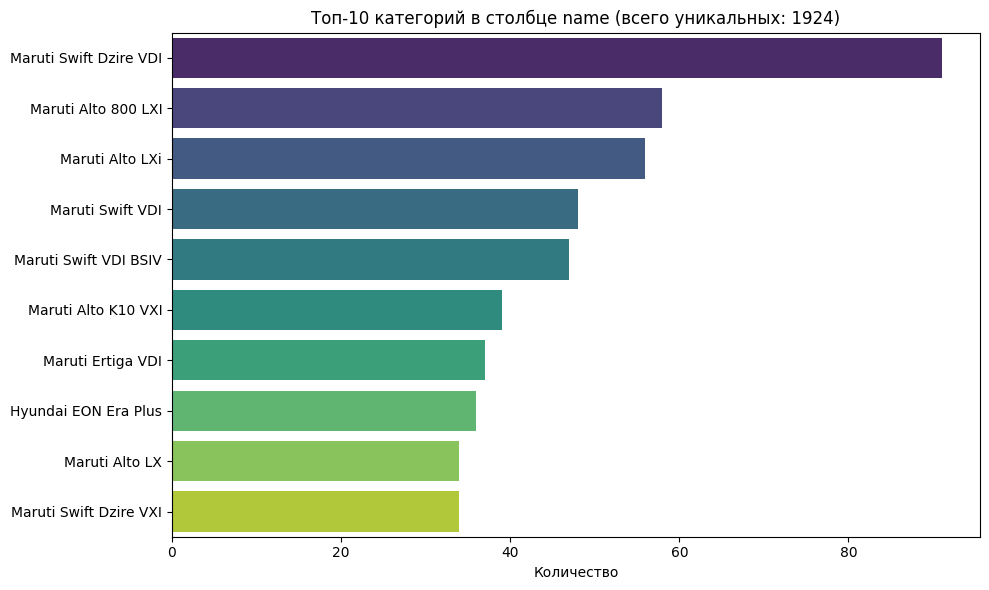

count                       5840
unique                      1924
top       Maruti Swift Dzire VDI
freq                          91
Name: name, dtype: object

In [37]:
top_n = 10
counts = df_train['name'].value_counts()

top_cats = counts.head(top_n)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_cats.values, y=top_cats.index, palette='viridis')

plt.title(f'Топ-{top_n} категорий в столбце name (всего уникальных: {len(counts)})')
plt.xlabel('Количество')
plt.ylabel('')
plt.tight_layout()
plt.show()

display(df_train["name"].describe())

In [38]:
train_brands = df_train['name'].astype(str).str.split().str[0].str.lower()
test_brands = df_test['name'].astype(str).str.split().str[0].str.lower()

print(f"Уникальных марок в train: {train_brands.nunique()}")
print(f"Уникальных марок в test: {test_brands.nunique()}")

unseen_in_train = set(test_brands.unique()) - set(train_brands.unique())
print(f"Марок в test, которых нет в train: {len(unseen_in_train)} -> {unseen_in_train}")
print("-" * 40)

print("Распределение марок в train:")
print(train_brands.value_counts())

Уникальных марок в train: 30
Уникальных марок в test: 25
Марок в test, которых нет в train: 2 -> {'opel', 'ashok'}
----------------------------------------
Распределение марок в train:
name
maruti           1804
hyundai          1058
mahindra          611
tata              534
toyota            309
ford              308
honda             308
chevrolet         188
renault           171
volkswagen        153
nissan             63
skoda              61
datsun             49
mercedes-benz      44
bmw                41
fiat               39
audi               31
jeep               20
mitsubishi          8
volvo               8
jaguar              7
force               4
isuzu               4
land                3
kia                 3
mg                  3
ambassador          3
daewoo              3
lexus               1
peugeot             1
Name: count, dtype: int64


In [39]:
X_train_cat = df_train.drop(columns=[target], errors='ignore').copy()
X_test_cat = df_test.drop(columns=[target], errors='ignore').copy()

for df in [X_train_cat, X_test_cat]:
    df['brand'] = df['name'].astype(str).str.split().str[0].str.lower()


X_train_cat.drop(columns=['name'], inplace=True)
X_test_cat.drop(columns=['name'], inplace=True)


brand_counts = X_train_cat['brand'].value_counts()
frequent_brands = brand_counts[brand_counts >= 10].index

X_train_cat['brand'] = X_train_cat['brand'].where(X_train_cat['brand'].isin(frequent_brands), 'other')
X_test_cat['brand'] = X_test_cat['brand'].where(X_test_cat['brand'].isin(frequent_brands), 'other')

print(f"Уникальных марок после очистки: {X_train_cat['brand'].nunique()}")


Уникальных марок после очистки: 19


In [40]:
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

train_brand_ohe = ohe.fit_transform(X_train_cat[['brand']])
test_brand_ohe = ohe.transform(X_test_cat[['brand']])

brand_cols = ohe.get_feature_names_out(['brand'])
train_brand_df = pd.DataFrame(train_brand_ohe, columns=brand_cols, index=X_train_cat.index)
test_brand_df = pd.DataFrame(test_brand_ohe, columns=brand_cols, index=X_test_cat.index)

X_train_cat = pd.concat([X_train_cat.drop(columns=['brand']), train_brand_df], axis=1)
X_test_cat = pd.concat([X_test_cat.drop(columns=['brand']), test_brand_df], axis=1)


In [41]:
# 14 столбцов после разбиения torque, минус selling_price; name предобработан в один столбец.
# Если из name получилось несколько столбцов — скорректируйте ожидаемую размерность.
assert X_train_cat.shape == (5840, 30)

In [42]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3177,5223,5336,3603


### **Задание 21 (0.1 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования.

In [43]:
cat_cols = X_train_cat.select_dtypes(include='object').columns.tolist()

ohe_cat = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

train_cat_ohe = ohe_cat.fit_transform(X_train_cat[cat_cols])
test_cat_ohe = ohe_cat.transform(X_test_cat[cat_cols])

ohe_cols = ohe_cat.get_feature_names_out(cat_cols)
train_cat_df = pd.DataFrame(train_cat_ohe, columns=ohe_cols, index=X_train_cat.index)
test_cat_df = pd.DataFrame(test_cat_ohe, columns=ohe_cols, index=X_test_cat.index)

X_train_cat = pd.concat([X_train_cat.drop(columns=cat_cols), train_cat_df], axis=1)
X_test_cat = pd.concat([X_test_cat.drop(columns=cat_cols), test_cat_df], axis=1)

print(X_train_cat.shape, X_test_cat.shape)

(5840, 36) (1000, 36)


### **Задание 22 (0.2 балла)**

OHE — базовый алгоритм преобразования категориальных признаков, но и с ним нужно быть аккуратными.

**Ответьте на вопросы:**


* Как корректно работать с OHE преобразованием?
* Почему мы удаляем один столбец?
* Пусть из категориального признака с $n$ категориями мы получили $n-1$ столбец, из которых $k < n-1$ оказались неважными по весам модели. Корректно ли их удалить?

1. Как корректно работать с OHE-преобразованием?
Применять OHE стоит только к номинальным категориальным признакам, значения которых нельзя упорядочить или сравнить на «больше/меньше» (например, марки авто: BMW и Audi). Уникальных категорий должно быть немного, чтобы избежать проклятия размерности и переобучения (редкие значения лучше заранее объединить в other). Кроме того, обучать кодировщик (fit) нужно строго на тренировочной выборке (train), а к тесту применять только transform с обработкой новых неизвестных категорий (handle_unknown='ignore'), чтобы не допустить утечки данных.
2. Почему мы удаляем один столбец?
Инженерное объяснение: последний столбец не несёт новой информации. Если известны значения всех n-1 столбцов (например, везде нули), мы однозначно знаем, что объект относится к оставшейся n-й категории. Лишний столбец только тратит память и даёт модели лишнюю степень свободы.
Математическое объяснение: при сохранении всех n столбцов возникает строгая мультиколлинеарность (сумма этих столбцов равна единице, что линейно зависимо со столбцом свободного члена). Из-за этого определитель матрицы Грама  становится равен 0, что делает невозможным нахождение точного аналитического решения в линейной регрессии и ухудшает ландшафт функции потерь при обучении. Особенно это критично в линейных моделях без регуляризации
3. Корректно ли удалить k < n-1 неважных столбцов?
Нет, удалять их просто по весам некорректно, так как эти столбцы образуют единую систему кодирования исходного признака, где веса оцениваются относительно базовой (удалённой) категории. Малый вес означает лишь то, что эти категории по влиянию на таргет близки к базовой, но в совокупности с другими признаками (или при взаимодействии фич) они могут давать важный эффект. Если их всё же нужно убрать, делать это стоит осознанно на этапе предобработки — например, объединив редкие или схожие категории в одну общую группу other.


### **Задание 23 (0.1 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [44]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

scaler = StandardScaler()
X_train_cat_scaled = scaler.fit_transform(X_train_cat)
X_test_cat_scaled = scaler.transform(X_test_cat)

param_grid = {
    'alpha': np.logspace(-3, 4, 50)
}

grid_ridge = GridSearchCV(
    estimator=Ridge(random_state=42),
    param_grid=param_grid,
    cv=10,
    scoring='r2',
    n_jobs=-1
)

grid_ridge.fit(X_train_cat_scaled, y_train)

print("Лучший alpha:", grid_ridge.best_params_['alpha'])
print("Лучший R2 на кросс-валидации:", grid_ridge.best_score_)

y_pred_train = grid_ridge.predict(X_train_cat_scaled)
y_pred_test = grid_ridge.predict(X_test_cat_scaled)

print("R2 train:", r2_score(y_train, y_pred_train))
print("R2 test:", r2_score(y_test, y_pred_test))
print("MSE train:", MSE(y_train, y_pred_train))
print("MSE test:", MSE(y_test, y_pred_test))

Лучший alpha: 0.001
Лучший R2 на кросс-валидации: 0.6935746506358875
R2 train: 0.7446960367093942
R2 test: 0.7397422789419017
MSE train: 73179903813.80212
MSE test: 149603569889.5798


После добавления закодированных категориальных признаков и выделения марки автомобиля (brand) из столбца name мы получили значительный прирост качества модели: метрика R2 на тестовой выборке выросла с 0.60 до 0.74, а ошибка MSE снизилась более чем на 35%. Главной причиной такого скачка стала качественная работа с признаками. Модель получила доступ к критически важной для ценообразования информации (марка авто, тип коробки передач, тип топлива и др.), при этом избежав проклятия размерности за счёт группировки редких марок в other. Разрыв между R2 на тренировочной (0.755) и тестовой (0.741) выборках минимален, что говорит об отсутствии переобучения и хорошей обобщающей способности модели, а малое значение коэффициента регуляризации (alpha = 0.001) подтверждает высокую информативность отобранных признаков.

# **Часть 4 (0.4 балла) | Feature Engineering**

### **Задание 24 (0.4 балла)**

В этой части домашнего задания вам предлагается проявить свою креативность для улучшения прогноза модели. Любые другие модели, кроме различных форм линейной (или полиномиальной) регрессии, использовать запрещается. А значит, придется работать с признаками

**Что можно попробовать сделать?** (каждый пункт — до 0.2 балла, но не больше 0.4 балла в сумме)

1.   *Сгенерировать новые признаки на основе уже существующих:*
    * посчитать произведения // частные признаков (кажется, что посчитать число "лошадей" на литр объема может быть полезно);
    * имеет смысл обратить внимание на визуализации в части с EDA (к примеру, зависимость цены от года выглядит квадратичной, а не линейной; значит, квадрат года нам, скорее всего, принесет больше пользы)

2.   *Добыть новые признаки:*
    * из названия автомобиля можно извлечь больше информации (например, спарсить инфу о классе автомобиля или каких-то специфических опциях)
    * можно добавить пороговые признаки вроде "владелец третий или больше" и объединить признаки в некоторые осмысленные правила, например "первый или второй владелец и продавец официальный дилер" (подбирать пороги удобно по диаграммам рассеяния)

3.   *Поработать с уже имеющимися:*
    * далеко не факт, что заполнить пропуск медианой было лучшей идеей (как минимум, можно добавить dummy-столбец для модели, сигнализирующий, что раньше на месте медианы был пропуск -- там где он был, конечно); попробуйте другие способы филлинга;
    * мы не анализировали, есть ли в данных выбросы => никак выбросы не обрабатывали; наиболее простым и, тем не менее, довольно полезным вариантом нахождения выбросов могут послужить boxplot'ы для каждого столбца; что делать с выбросами думайте сами :) -- вариантов довольно много
    * мы толком не смотрели на таргет сам по себе; в нем тоже могут быть неожиданности -- стоит хотя бы проверить
    * можно заметить, что некоторые признаки распределены совсем не нормально; возможно их стоит отлогарифмировать

И так далее...

Feel Free to Try!

In [45]:
def evaluate_ridge(X_tr, y_tr, X_te, y_te, step_name, log_target=False):
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s = scaler.transform(X_te)
    
    y_fit = np.log1p(y_tr) if log_target else y_tr
    
    grid = GridSearchCV(
        estimator=Ridge(random_state=42),
        param_grid={'alpha': np.logspace(-3, 4, 50)},
        cv=10,
        scoring='r2',
        n_jobs=-1
    )
    grid.fit(X_tr_s, y_fit)
    
    pred_tr = grid.predict(X_tr_s)
    pred_te = grid.predict(X_te_s)
    
    if log_target:
        pred_tr = np.expm1(pred_tr)
        pred_te = np.expm1(pred_te)
        
    print(f"=== {step_name} ===")
    print(f"Признаков: {X_tr.shape} | Лучший alpha: {grid.best_params_['alpha']:.4f}")
    print(f"R2 train: {r2_score(y_tr, pred_tr):.4f} | R2 test: {r2_score(y_te, pred_te):.4f}")
    print(f"MSE train: {MSE(y_tr, pred_tr):.2e} | MSE test: {mean_squared_error(y_te, pred_te):.2e}\n")
    return grid.best_estimator_

In [46]:
# 1 вариант 
X_tr_1 = X_train_cat.copy()
X_te_1 = X_test_cat.copy()

for df_feat in [X_tr_1, X_te_1]:
    df_feat['power_per_engine'] = df_feat['max_power'] / (df_feat['engine'] + 1e-5)
    df_feat['age'] = 2020 - df_feat['year']
    df_feat['age_sq'] = df_feat['age'] ** 2
    df_feat['km_per_year'] = df_feat['km_driven'] / (df_feat['age'] + 1)
    df_feat['power_x_year'] = df_feat['max_power'] * df_feat['age'] # учитывает обесценивание мощных машин

m1 = evaluate_ridge(X_tr_1, y_train, X_te_1, y_test, "Этап 1: Полиномы и отношения")

=== Этап 1: Полиномы и отношения ===
Признаков: (5840, 41) | Лучший alpha: 0.0010
R2 train: 0.8514 | R2 test: 0.8510
MSE train: 4.26e+10 | MSE test: 8.56e+10



In [47]:
#2 d
X_tr_2 = X_tr_1.copy()
X_te_2 = X_te_1.copy()

lux_brands = {'bmw', 'mercedes-benz', 'audi', 'volvo', 'jaguar', 'land', 'lexus', 'porsche', 'jeep'}

for df_raw, df_feat in [(df_train, X_tr_2), (df_test, X_te_2)]:
    name_lower = df_raw['name'].astype(str).str.lower()
    brand = name_lower.str.split().str.get(0)
    
    df_feat['is_luxury'] = brand.isin(lux_brands).astype(int)
    df_feat['first_owner_dealer'] = ((df_raw['owner'] == 'First Owner') & (df_raw['seller_type'].isin(['Dealer', 'Trustmark Dealer']))).astype(int)

m2 = evaluate_ridge(X_tr_2, y_train, X_te_2, y_test, "Этап 2: Доменные правила и сегменты")

=== Этап 2: Доменные правила и сегменты ===
Признаков: (5840, 43) | Лучший alpha: 19.3070
R2 train: 0.8633 | R2 test: 0.8706
MSE train: 3.92e+10 | MSE test: 7.44e+10



In [48]:
X_tr_3 = X_tr_2.copy()
X_te_3 = X_te_2.copy()

km_cap = X_tr_3['km_driven'].quantile(0.99)
torque_cap = X_tr_3['torque'].quantile(0.99)

for df_feat in [X_tr_3, X_te_3]:
    df_feat['km_driven'] = np.clip(df_feat['km_driven'], None, km_cap)
    df_feat['torque'] = np.clip(df_feat['torque'], None, torque_cap)
    
    for col in ['km_driven', 'max_power', 'engine', 'torque']:
        df_feat[f'log_{col}'] = np.log1p(np.maximum(df_feat[col], 0))

m3 = evaluate_ridge(X_tr_3, y_train, X_te_3, y_test, "Этап 3 (без log таргета): Логарифмирование фичей и клиппинг выбросов", log_target=False)
m4 = evaluate_ridge(X_tr_3, y_train, X_te_3, y_test, "Этап 3 (с log таргета): Логарифмирование фичей + log1p(target)", log_target=True)


=== Этап 3 (без log таргета): Логарифмирование фичей и клиппинг выбросов ===
Признаков: (5840, 47) | Лучший alpha: 13.8950
R2 train: 0.8661 | R2 test: 0.8724
MSE train: 3.84e+10 | MSE test: 7.34e+10

=== Этап 3 (с log таргета): Логарифмирование фичей + log1p(target) ===
Признаков: (5840, 47) | Лучший alpha: 13.8950
R2 train: 0.8996 | R2 test: 0.9434
MSE train: 2.88e+10 | MSE test: 3.25e+10



In [49]:
class CarPricePredictor:
    def __init__(self, alpha=10.0, min_brand_freq=10):
        self.alpha = alpha
        self.min_brand_freq = min_brand_freq
        self.medians = {}
        self.top_brands = set()
        self.km_cap = None
        self.torque_cap = None
        self.ohe_seats = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
        self.ohe_cat = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
        self.scaler = StandardScaler()
        self.model = Ridge(alpha=self.alpha, random_state=42)
        self.feature_columns = []

    def _parse_raw(self, df):
        data = df.copy()
        for col in ['mileage', 'engine', 'max_power']:
            data[col] = data[col].astype(str).str.extract(r'(\d+\.?\d*)').astype(float)

        s = data['torque'].astype(str).str.replace(',', '')
        data['torque'] = s.str.extract(r'^(\d+\.?\d*)').astype(float)
        data.loc[s.str.contains('kgm', case=False, na=False), 'torque'] *= 9.80665
        data['max_torque_rpm'] = s.str.extract(r'(\d+\.?\d*)\s*rpm', flags=2).astype(float)
        return data

    def _build_features(self, df, is_train=False):
        raw_name_lower = df['name'].astype(str).str.lower()
        brand = raw_name_lower.str.split().str.get(0)

        data = self._parse_raw(df)

        num_cols_to_fill = ['mileage', 'engine', 'max_power', 'torque', 'seats', 'max_torque_rpm']
        for col in num_cols_to_fill:
            if is_train:
                self.medians[col] = data[col].median()
            data[col] = data[col].fillna(self.medians[col])

        data['engine'] = data['engine'].astype(int)
        data['seats'] = data['seats'].astype(int)

        if is_train:
            brand_counts = brand.value_counts()
            self.top_brands = set(brand_counts[brand_counts >= self.min_brand_freq].index)

        data['name'] = brand.where(brand.isin(self.top_brands), 'other')

        if is_train:
            seats_arr = self.ohe_seats.fit_transform(data[['seats']])
        else:
            seats_arr = self.ohe_seats.transform(data[['seats']])
        seats_df = pd.DataFrame(seats_arr, columns=self.ohe_seats.get_feature_names_out(['seats']), index=data.index)
        data = pd.concat([data.drop(columns=['seats']), seats_df], axis=1)

        cat_cols = ['name', 'fuel', 'seller_type', 'transmission', 'owner']
        if is_train:
            cat_arr = self.ohe_cat.fit_transform(data[cat_cols])
        else:
            cat_arr = self.ohe_cat.transform(data[cat_cols])
        cat_df = pd.DataFrame(cat_arr, columns=self.ohe_cat.get_feature_names_out(cat_cols), index=data.index)
        data = pd.concat([data.drop(columns=cat_cols), cat_df], axis=1)

        data['power_per_engine'] = data['max_power'] / (data['engine'] + 1e-5)
        data['age'] = 2020 - data['year']
        data['age_sq'] = data['age'] ** 2
        data['km_per_year'] = data['km_driven'] / (data['age'] + 1)
        data['power_x_year'] = data['max_power'] * data['age']

        lux_brands = {'bmw', 'mercedes-benz', 'audi', 'volvo', 'jaguar', 'land', 'lexus', 'porsche', 'jeep'}
        data['is_luxury'] = brand.isin(lux_brands).astype(int)
        data['is_top_trim'] = raw_name_lower.str.contains(r'\b(?:zxi|zdi|zx|vx|sx|alpha|titanium|top|awd|4wd|4x4|quattro)\b', regex=True).astype(int)
        data['owner_3plus'] = df['owner'].isin(['Third Owner', 'Fourth & Above Owner']).astype(int)
        data['first_owner_dealer'] = ((df['owner'] == 'First Owner') & (df['seller_type'].isin(['Dealer', 'Trustmark Dealer']))).astype(int)

        if is_train:
            self.km_cap = data['km_driven'].quantile(0.99)
            self.torque_cap = data['torque'].quantile(0.99)

        data['km_driven'] = np.clip(data['km_driven'], None, self.km_cap)
        data['torque'] = np.clip(data['torque'], None, self.torque_cap)

        for col in ['km_driven', 'max_power', 'engine', 'torque']:
            data[f'log_{col}'] = np.log1p(np.maximum(data[col], 0))

        return data

    def fit(self, df_train, target_col='selling_price'):
        X = df_train.drop(columns=[target_col])
        y = np.log1p(df_train[target_col])
        X_feat = self._build_features(X, is_train=True)
        self.feature_columns = X_feat.columns.tolist()
        X_scaled = self.scaler.fit_transform(X_feat)
        self.model.fit(X_scaled, y)
        return self

    def predict(self, df_new):
        X = df_new.drop(columns=['selling_price'], errors='ignore')
        X_feat = self._build_features(X, is_train=False)
        X_feat = X_feat.reindex(columns=self.feature_columns, fill_value=0)
        X_scaled = self.scaler.transform(X_feat)
        pred_log = self.model.predict(X_scaled)
        return np.expm1(pred_log)


In [50]:
import pickle

df_tr_raw = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_te_raw = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

feature_cols = [c for c in df_tr_raw.columns if c != 'selling_price']
df_tr_raw = df_tr_raw.drop_duplicates(subset=feature_cols, keep='first').reset_index(drop=True)

predictor = CarPricePredictor(alpha=10.0)
predictor.fit(df_tr_raw)

preds_test = predictor.predict(df_te_raw)
print(f"R2 test: {r2_score(df_te_raw['selling_price'], preds_test):.4f}")
print(f"MSE test: {MSE(df_te_raw['selling_price'], preds_test):.2e}")

new_car = pd.DataFrame([{
    'name': 'UnknownBrand X5 ZXI',
    'year': 2018,
    'km_driven': 35000,
    'fuel': 'Diesel',
    'seller_type': 'Individual',
    'transmission': 'Automatic',
    'owner': 'First Owner',
    'mileage': '18.5 kmpl',
    'engine': '1995 CC',
    'max_power': '190 bhp',
    'torque': np.nan,
    'seats': 5.0
}])


with open('model.pkl', 'wb') as f:
    pickle.dump(predictor, f)

with open('model.pkl', 'rb') as f:
    loaded_predictor = pickle.load(f)

print("Разница предсказаний:", np.max(np.abs(preds_test - loaded_predictor.predict(df_te_raw))))


R2 test: 0.9438
MSE test: 3.23e+10
Разница предсказаний: 0.0


# **Часть 5 | Бизнесовая (0.4 балла)**

### **Задание 25 (0.2 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metrics}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metrics`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [51]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

def business_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    rel_error = np.abs(y_pred - y_true) / y_true
    return np.mean(rel_error <= 0.1)

m1 = make_pipeline(StandardScaler(), Ridge(alpha=0.001)).fit(X_tr_1, y_train)
m2 = make_pipeline(StandardScaler(), Ridge(alpha=0.001)).fit(X_tr_2, y_train)
m3 = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(X_tr_3, y_train)

models = [
    ("Этап 1 (Полиномы)", m1, X_te_1),
    ("Этап 2 (Доменные правила)", m2, X_te_2),
    ("Этап 3 (Клиппинг + log фичей)", m3, X_te_3),
    ("Финальный predictor ", predictor, df_te_raw)
]

for count, (name, m, data) in enumerate(models, start=1):
    preds_test = m.predict(data)
    score = business_metrics(df_te_raw['selling_price'], preds_test)
    print(f"Модель {count} [{name}]: business_metrics = {score:.4f} ({score * 100:.2f}%)")


Модель 1 [Этап 1 (Полиномы)]: business_metrics = 0.2910 (29.10%)
Модель 2 [Этап 2 (Доменные правила)]: business_metrics = 0.2970 (29.70%)
Модель 3 [Этап 3 (Клиппинг + log фичей)]: business_metrics = 0.3140 (31.40%)
Модель 4 [Финальный predictor ]: business_metrics = 0.3760 (37.60%)


### **Задание 26 (0.2 балла)**

Но у бизнеса не всегда есть идеи и иногда задача на выбор метрики делегируется вам.

**Задание:**

- [ ] Придумайте и реализуйте другую кастомную метрику с учетом того, что модель не должна сильно ошибаться в прогнозе, но недопрогноз для модели, согласно мнению бизнеса, хуже, чем перепрогноз.
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

Внесу предположение, что для нас страшно, если мы продадим слишком дешево и потеряем маржу , то есть мы не боимся сделать цену больше реальной продажи (перепрогноз), но боимся сделать цену ниже (недопрогноз). В таком случае выбираю персентильную функцию потерь с r > 0.5

In [52]:
def your_business_metrics(y_true, y_pred, r):
    diff = np.asarray(y_true).ravel() - np.asarray(y_pred).ravel()
    return np.mean(np.maximum(r * diff, (r - 1) * diff))

In [53]:
m1 = make_pipeline(StandardScaler(), Ridge(alpha=0.001)).fit(X_tr_1, y_train)
m2 = make_pipeline(StandardScaler(), Ridge(alpha=0.001)).fit(X_tr_2, y_train)
m3 = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(X_tr_3, y_train)

models = [
    ("Этап 1 (Полиномы)", m1, X_te_1),
    ("Этап 2 (Доменные правила)", m2, X_te_2),
    ("Этап 3 (Клиппинг + log фичей)", m3, X_te_3),
    ("Финальный predictor ", predictor, df_te_raw)
]

for count, (name, m, data) in enumerate(models, start=1):
    preds_test = m.predict(data)
    score = your_business_metrics(df_te_raw['selling_price'], preds_test,0.8)
    print(f"Модель {count} [{name}]: business_metrics = {score:.4f} ({score * 100:.2f}%)")

Модель 1 [Этап 1 (Полиномы)]: business_metrics = 80836.5891 (8083658.91%)
Модель 2 [Этап 2 (Доменные правила)]: business_metrics = 71333.9741 (7133397.41%)
Модель 3 [Этап 3 (Клиппинг + log фичей)]: business_metrics = 71497.7929 (7149779.29%)
Модель 4 [Финальный predictor ]: business_metrics = 55490.8329 (5549083.29%)


Ранжирование поменялось но модель 4 оказалсь лучшей в любом случае по бизнес метрике

# **Часть 6 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

# **<font color="green">Часть 7 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 6 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 6 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.